# Lista 4 — Modelos Lineares Generalizados

Resolução dos 6 exercícios do `Enunciado.md` (Gilberto A. Paula, versão 2025, Capítulos 4 e 5).

| Exercício | Livro | Dados | Modelo |
|---|---|---|---|
| 1 | Cap. 5, Ex. 5 | `L4-Q1-C5-EX5-nasal.txt` | Poisson log-linear com offset (GAMLSS) |
| 2 | Cap. 5, Ex. 22 | `L4-Q2-C5-EX22-nitrofen.txt` | Poisson |
| 3 | Cap. 5, Ex. 7 | `L4-Q3-C5-EX7-rolos.txt` | Poisson e binomial negativa |
| 4 | Cap. 4, Ex. 10 | `L4-Q4-C4-EX10-sementes.txt` | Logístico (binomial) |
| 5 | Cap. 4, Ex. 21 | `L4-Q5-C4-EX21-leuce.txt` | Logístico (Bernoulli) |
| 6 | Cap. 4, Ex. 24 | `L4-Q6-C4-EX24-grahani.txt` | Logístico e beta-binomial (GAMLSS) |

Como no notebook o `identify` não funciona, os gráficos de diagnóstico escrevem o número das observações que mais se destacam.

In [1]:
library(MASS)     # glm.nb, stepAIC, rnegbin
library(gamlss)   # gamlss, rqres.plot, term.plot, wp

# Caminho da pasta da Lista 4
caminho <- "C:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MLG/Lista 4/"

Carregando pacotes exigidos: splines

Carregando pacotes exigidos: gamlss.data


Anexando pacote: 'gamlss.data'


O seguinte objeto é mascarado por 'package:datasets':

    sleep


Carregando pacotes exigidos: gamlss.dist

Carregando pacotes exigidos: nlme

Carregando pacotes exigidos: parallel

 **********   GAMLSS Version 5.5-0  ********** 

For more on GAMLSS look at https://www.gamlss.com/

Type gamlssNews() to see new features/changes/bug fixes.




Carregamos o `MASS` (binomial negativa, `stepAIC` e geração de dados binomial negativa para o envelope) e o `gamlss` (pedido nos exercícios 1 e 6). O `caminho` aponta para a pasta onde estão os `.txt`; se mudar a pasta de lugar, basta alterar essa linha.

### Funções auxiliares de diagnóstico

Para não repetir o mesmo código em todos os exercícios, definimos duas funções que valem para `glm` Poisson, binomial e binomial negativa (`glm.nb`):

- `diag_glm(fit)`: painel 2×2 com **alavanca** $h_{ii}$ (referência $2p/n$), **resíduo componente do desvio padronizado** $t_{D_i}$ (referência $\pm 2$), **distância de Cook** e $t_{D_i}$ contra o preditor linear (com tendência `lowess`).
- `envelope_glm(fit)`: **gráfico normal de probabilidades com envelope simulado** (como os do livro do Paula): gera 100 amostras do modelo ajustado, reajusta, e usa o mínimo, a mediana e o máximo dos resíduos ordenados como bandas.

In [2]:
diag_glm <- function(fit, k = 3, titulo = "") {
  h  <- hatvalues(fit)
  td <- rstandard(fit, type = "deviance")   # componente do desvio padronizado
  ck <- cooks.distance(fit)
  p <- length(coef(fit)); n <- length(h)
  rot <- function(x, y, v) { d <- order(abs(v), decreasing = TRUE)[1:k]; text(x[d], y[d], labels = d, pos = 3, cex = 0.8) }
  par(mfrow = c(2, 2))
  plot(fitted(fit), h, xlab = "Valores ajustados", ylab = "Alavanca", pch = 16, main = titulo)
  abline(h = 2 * p / n, lty = 2); rot(fitted(fit), h, h)
  plot(td, xlab = "Índice", ylab = "Resíduo do desvio padronizado", pch = 16, ylim = range(td, -2.5, 2.5))
  abline(h = c(-2, 0, 2), lty = c(2, 3, 2)); rot(seq_along(td), td, td)
  plot(ck, xlab = "Índice", ylab = "Distância de Cook", pch = 16); rot(seq_along(ck), ck, ck)
  plot(predict(fit), td, xlab = "Preditor linear", ylab = "Resíduo do desvio padronizado", pch = 16)
  abline(h = c(-2, 0, 2), lty = c(2, 3, 2)); lines(lowess(predict(fit), td), col = "red")
  par(mfrow = c(1, 1))
  cat("Referência 2p/n =", round(2 * p / n, 3), "\n")
  invisible(data.frame(h = h, td = td, cook = ck))
}

envelope_glm <- function(fit, nsim = 100, main = "Envelope", semente = 123) {
  set.seed(semente)
  td <- rstandard(fit, type = "deviance")
  n <- length(td); X <- model.matrix(fit); mu <- fitted(fit)
  off <- if (is.null(fit$offset)) rep(0, n) else fit$offset
  nb <- inherits(fit, "negbin"); fam <- family(fit)$family
  e <- matrix(NA, n, nsim)
  for (i in 1:nsim) {
    if (nb) {
      ys <- rnegbin(n, mu = mu, theta = fit$theta)
      fs <- tryCatch(suppressWarnings(glm.nb(ys ~ X - 1 + offset(off))), error = function(err) NULL)
    } else if (fam == "poisson") {
      ys <- rpois(n, mu)
      fs <- suppressWarnings(glm(ys ~ X - 1, family = family(fit), offset = off))
    } else if (fam == "binomial") {
      m <- fit$prior.weights; ys <- rbinom(n, m, mu)
      fs <- suppressWarnings(glm(cbind(ys, m - ys) ~ X - 1, family = family(fit), offset = off))
    }
    if (!is.null(fs)) e[, i] <- sort(rstandard(fs, type = "deviance"))
  }
  e <- e[, colSums(is.na(e)) == 0, drop = FALSE]
  lim <- t(apply(e, 1, function(x) c(min(x), median(x), max(x))))
  q <- qnorm((1:n - 0.375) / (n + 0.25))
  tds <- sort(td)
  fora <- sum(tds < lim[, 1] | tds > lim[, 3])
  plot(q, tds, xlab = "Percentil da N(0,1)", ylab = "Componente do desvio padronizado",
       ylim = range(tds, lim), pch = 16, main = main)
  lines(q, lim[, 1]); lines(q, lim[, 3]); lines(q, lim[, 2], lty = 2)
  cat("Pontos fora do envelope:", fora, "de", n, sprintf("(%.1f%%)\n", 100 * fora / n))
  invisible(fora)
}

As duas funções ficam disponíveis para o resto do notebook. Em `envelope_glm` a semente é fixa (`123`), então o envelope sai igual cada vez que roda. A função também imprime quantos pontos ficaram fora das bandas: com 100 simulações e bandas de mínimo/máximo, espera-se poucos pontos fora (em torno de 5% ou menos) quando o modelo está bem ajustado.

---
# Exercício 1 — Câncer nasal (Cap. 5, Ex. 5)

Estudo de seguimento de trabalhadores de uma refinaria de níquel no País de Gales (Breslow e Day, 1987). Para cada combinação de

- `idade`: idade no primeiro emprego (4 níveis),
- `ano`: ano do primeiro emprego (4 níveis),
- `tempo`: tempo decorrido desde o primeiro emprego (5 níveis),

temos o número de casos de câncer nasal (`casos`) e o total de pessoas-anos (`panos`).

Modelo: $Y_{ijk} \sim \text{Poisson}(\mu_{ijk})$, com
$$\log \mu_{ijk} = \log(\text{panos}_{ijk}) + \alpha + \beta_i + \gamma_j + \delta_k,$$
ou seja, $\log(\mu/\text{panos})$ (log da **taxa** anual) é aditivo nos três fatores. $e^{\beta_i}$, $e^{\gamma_j}$ e $e^{\delta_k}$ são **razões de taxas** em relação ao nível de referência (nível 1).

In [3]:
nasal <- read.table(paste0(caminho, "L4-Q1-C5-EX5-nasal.txt"), header = TRUE)
nasal$idade <- factor(nasal$idade)
nasal$ano   <- factor(nasal$ano)
nasal$tempo <- factor(nasal$tempo)
str(nasal)
summary(nasal)

'data.frame':	71 obs. of  5 variables:
 $ idade: Factor w/ 4 levels "1","2","3","4": 1 1 1 1 1 1 1 1 1 1 ...
 $ ano  : Factor w/ 4 levels "1","2","3","4": 1 1 1 1 2 2 2 2 2 3 ...
 $ tempo: Factor w/ 5 levels "1","2","3","4",..: 2 3 4 5 1 2 3 4 5 1 ...
 $ casos: int  0 0 0 0 0 1 0 1 0 0 ...
 $ panos: num  19.41 70 52.84 33.21 2.17 ...


 idade  ano    tempo      casos            panos         
 1:19   1:15   1:12   Min.   :0.0000   Min.   :   2.166  
 2:19   2:19   2:16   1st Qu.:0.0000   1st Qu.:  51.145  
 3:18   3:18   3:16   Median :0.0000   Median : 151.760  
 4:15   4:19   4:16   Mean   :0.7746   Mean   : 214.506  
               5:11   3rd Qu.:1.0000   3rd Qu.: 273.623  
                      Max.   :5.0000   Max.   :1088.072  

São 71 combinações (a tabela não é completa: algumas combinações de ano × tempo não existem). Há muitos zeros em `casos` (a maioria das células tem 0 ou 1 caso) e `panos` varia muito (de cerca de 2 até mais de 1000), por isso o offset $\log(\text{panos})$ é essencial: compara taxas, não contagens brutas.

In [4]:
# taxa observada por 1000 pessoas-anos, por nível de cada fator
taxa <- function(f) with(nasal, round(1000 * tapply(casos, f, sum) / tapply(panos, f, sum), 2))
list(idade = taxa(nasal$idade), ano = taxa(nasal$ano), tempo = taxa(nasal$tempo))

$idade
    1     2     3     4 
 0.65  2.83  5.12 10.26 

$ano
   1    2    3    4 
5.64 8.95 3.49 1.24 

$tempo
   1    2    3    4    5 
0.39 3.98 3.93 5.28 4.65

Descritivamente a taxa de câncer nasal **cresce com a idade no primeiro emprego**, é **bem menor para quem entrou no último período (ano = 4)** e é **muito baixa no primeiro nível de tempo desde o primeiro emprego** (0,39 por 1000 pessoas-anos), ficando em torno de 4 a 5 nos demais. Essas taxas marginais não controlam os outros fatores; o modelo log-linear faz isso.

## 1.1 Modelo com os três fatores (`fit1.nasal`)

In [5]:
fit1.nasal <- gamlss(casos ~ idade + ano + tempo + offset(log(panos)), family = PO, data = nasal, trace = FALSE)
summary(fit1.nasal)

******************************************************************
Family:  c("PO", "Poisson") 

Call:  gamlss(formula = casos ~ idade + ano + tempo + offset(log(panos)),  
    family = PO, data = nasal, trace = FALSE) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -9.13152    1.31882  -6.924 3.37e-09 ***
idade2       1.61161    0.75165   2.144  0.03609 *  
idade3       2.34833    0.75968   3.091  0.00302 ** 
idade4       3.34327    0.77978   4.287 6.66e-05 ***
ano2         0.59740    0.37173   1.607  0.11328    
ano3        -0.09357    0.48322  -0.194  0.84711    
ano4        -1.14703    0.45372  -2.528  0.01412 *  
tempo2       1.59449    1.04864   1.521  0.13363    
tempo3       1.74015    1.05664   1.647  0.10481    
tempo4       2.33358    1.07154   2.178  0.03337 *  
tempo5       2.59881    1.13441   2.291  0.02550 *  
---
Signif. c

Estimativas (escala log), que são as mesmas do `glm` Poisson:

- **idade**: efeitos crescentes e significativos (≈ 1,61; 2,35; 3,34 para os níveis 2, 3 e 4).
- **ano**: nível 2 com efeito positivo não significativo, nível 3 praticamente igual ao nível 1, e **nível 4 negativo e significativo** (≈ −1,15).
- **tempo**: efeitos crescentes (≈ 1,59; 1,74; 2,33; 2,60), mas os níveis 2 e 3 não são significativos isoladamente (o nível 1 tem pouquíssimas pessoas-anos, por isso os erros-padrão são grandes).

Desvio residual ≈ 51,6 com 60 g.l. e AIC ≈ 144,8.

In [6]:
# mesmo modelo via glm para usar as ferramentas de diagnóstico do curso
fit1.glm <- glm(casos ~ idade + ano + tempo + offset(log(panos)), family = poisson, data = nasal)
c(desvio = deviance(fit1.glm), gl = df.residual(fit1.glm),
  desvio_gl = deviance(fit1.glm) / df.residual(fit1.glm),
  p_valor = 1 - pchisq(deviance(fit1.glm), df.residual(fit1.glm)))
drop1(fit1.glm, test = "Chisq")

desvio         gl  desvio_gl    p_valor 
51.6015549 60.0000000  0.8600259  0.7715720

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,51.60155,144.8305,NA,NA
idade,3,86.55667,173.7856,34.95512,1.245140e-07
ano,3,76.65388,163.8828,25.05233,1.505634e-05
tempo,4,62.23442,147.4634,10.63286,3.101525e-02


- **Qualidade do ajuste:** $D = 51{,}6$ com 60 g.l. ($D/\text{gl} \approx 0{,}86$, p ≈ 0,77). Não há indício de falta de ajuste nem de **sobredispersão** (com contagens tão pequenas o teste do desvio é só indicativo, mas não sugere problema).
- **Testes da razão de verossimilhanças:** os três fatores são significativos: idade (p ≈ 1e−7), ano (p ≈ 1,5e−5) e tempo (p ≈ 0,03).

### Análise de resíduos do `fit1.nasal`

******************************************************************
	 Summary of the Randomised Quantile Residuals
                           mean   =  0.04197484 
                       variance   =  1.036248 
               coef. of skewness  =  -0.2134178 
               coef. of kurtosis  =  2.277792 
Filliben correlation coefficient  =  0.9912183 
******************************************************************


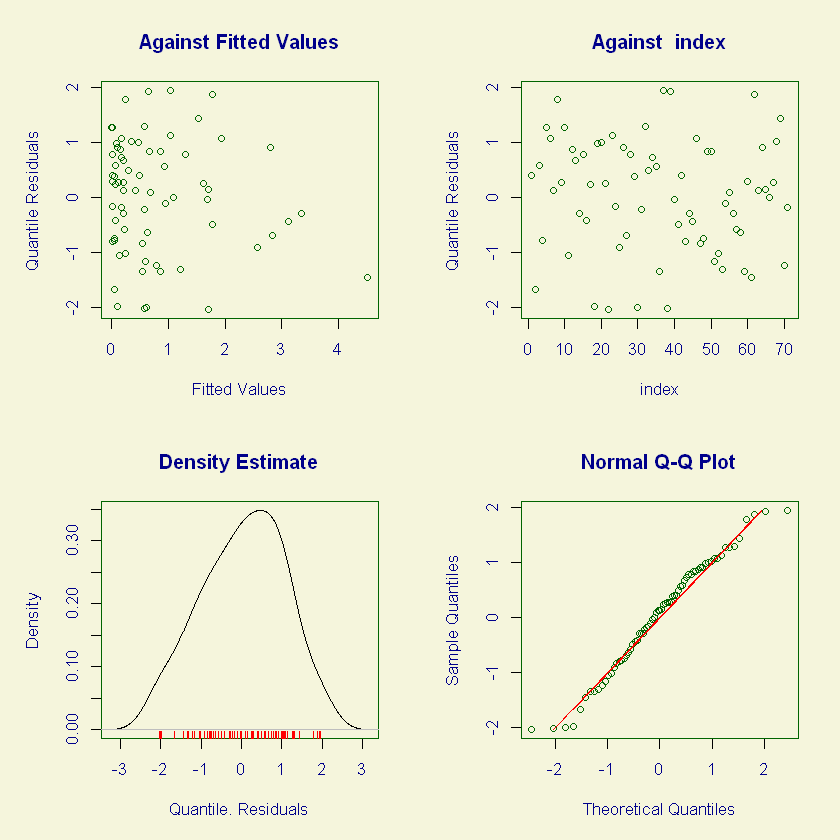

In [7]:
plot(fit1.nasal)

O `plot` do GAMLSS usa os **resíduos quantílicos aleatorizados** (para Poisson são aleatorizados por causa da natureza discreta). Os resíduos ficam espalhados em torno de zero sem tendência contra os valores ajustados e contra o índice, a densidade é aproximadamente simétrica e o QQ-plot fica próximo da reta. Os resumos impressos (média ≈ 0, variância ≈ 1, assimetria e curtose próximas de 0 e 3) são compatíveis com $N(0,1)$.

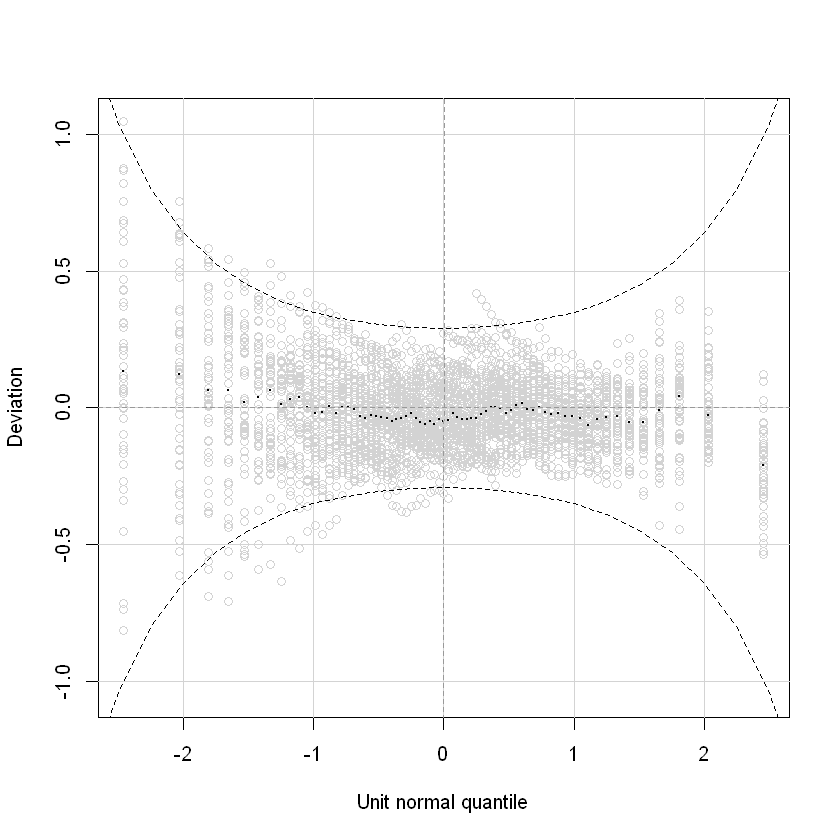

In [8]:
rqres.plot(fit1.nasal, howmany = 50, plot = "all")

Como os resíduos quantílicos de uma Poisson são aleatorizados, cada realização muda um pouco. O `rqres.plot` com `howmany = 50` sobrepõe 50 realizações: os pontos ficam em torno da reta do QQ-plot em todas elas, sem desvio sistemático, então o ajuste não depende de uma realização "sortuda".

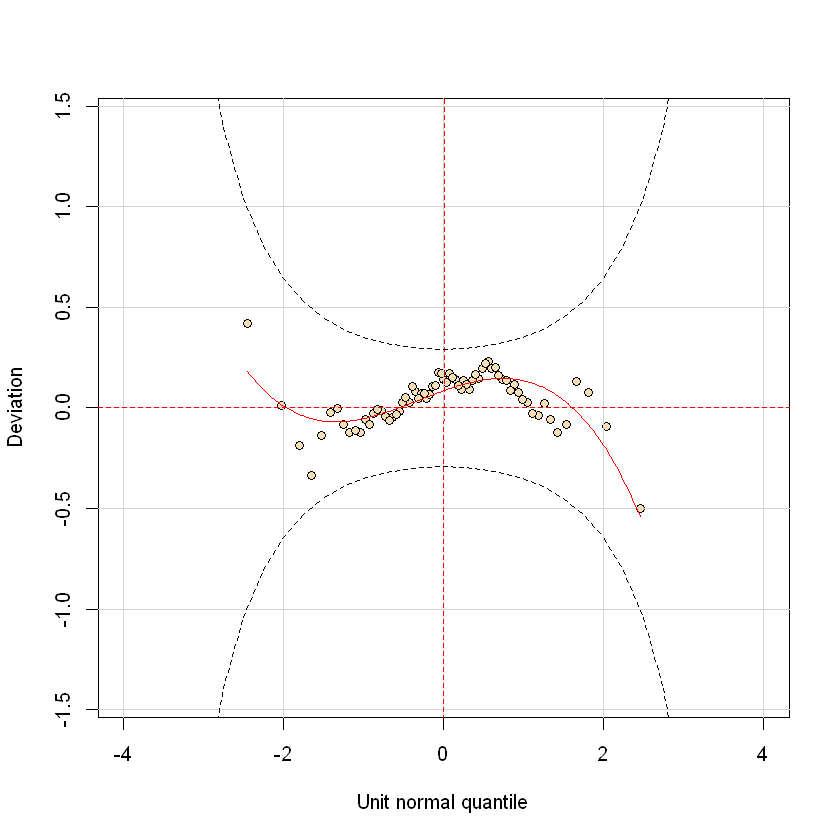

In [9]:
wp(fit1.nasal)

No *worm plot* (QQ-plot "sem tendência") os pontos ficam dentro das curvas de 95% e sem forma de U ou S marcada, sem indicação de problema de dispersão ou de assimetria.

Referência 2p/n = 0.31 


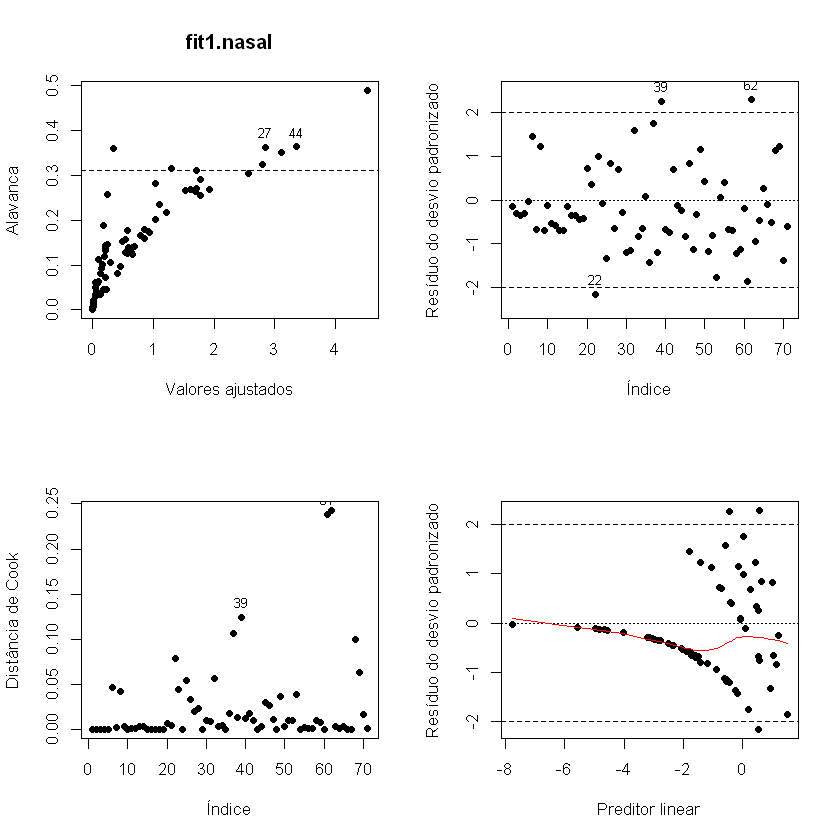

In [10]:
d1 <- diag_glm(fit1.glm, titulo = "fit1.nasal")

- **Alavanca:** a referência é $2p/n = 22/71 \approx 0{,}31$. As observações **61, 44 e 27** ficam um pouco acima (máximo ≈ 0,49), mas são células com muitas pessoas-anos e pertencem a combinações com poucas células; não é preocupante.
- **Resíduos:** quase todos em $[-2, 2]$; destacam-se **62, 39 e 22** (|t| ≈ 2,2–2,3). A obs. 62 tem 5 casos em apenas 56 pessoas-anos (taxa muito alta).
- **Cook:** as maiores são 62 e 61 (≈ 0,24), sem nenhum valor isolado muito grande.
- **Resíduo × preditor linear:** sem tendência marcada (a faixa inferior de pontos é o padrão típico das contagens zero).

Pontos fora do envelope: 0 de 71 (0.0%)


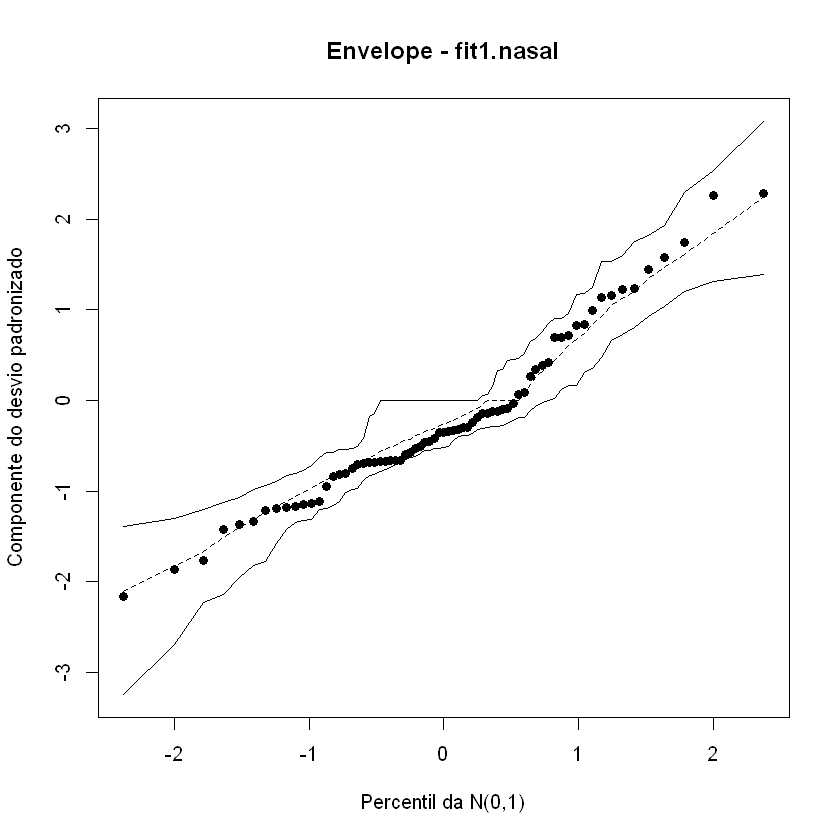

In [11]:
envelope_glm(fit1.glm, main = "Envelope - fit1.nasal")

Todos os pontos ficam **dentro do envelope** (0 de 71 fora). O modelo Poisson com os três fatores está **bem ajustado**, então podemos seguir e tentar agrupar níveis.

## 1.2 Agrupamento de níveis (`fit2.nasal`)

Pelas estimativas do `fit1.nasal`:

- **tempo**: os níveis 1, 2 e 3 (0–39,9 anos) têm efeitos parecidos entre si, e os níveis 4 e 5 são mais altos;
- **ano**: os níveis 1, 2 e 3 (1902–1919) são parecidos, e o nível 4 (1920–1924) se destaca com taxa menor.

Agrupamos como sugerido no enunciado.

In [ ]:
nasal$ntempo <- nasal$tempo
levels(nasal$ntempo) <- c("0-39,9", "0-39,9", "0-39,9", "40-49,9", "50+")
nasal$nano <- nasal$ano
levels(nasal$nano) <- c("1902-1919", "1902-1919", "1902-1919", "1920-1924")
table(nasal$ntempo, nasal$tempo)
table(nasal$nano, nasal$ano)

         
           1  2  3  4  5
  0-39,9  12 16 16  0  0
  40-49,9  0  0  0 16  0
  50+      0  0  0  0 11

           
             1  2  3  4
  1902-1919 15 19 18  0
  1920-1924  0  0  0 19

As tabelas cruzadas confirmam o agrupamento: `ntempo` junta os níveis 1–3 de `tempo` em "0-39,9" e mantém 4 e 5; `nano` junta os níveis 1–3 de `ano` em "1902-1919" e mantém o 4 como "1920-1924".

In [13]:
fit2.nasal <- gamlss(casos ~ idade + nano + ntempo + offset(log(panos)), family = PO, data = nasal, trace = FALSE)
summary(fit2.nasal)

******************************************************************
Family:  c("PO", "Poisson") 

Call:  gamlss(formula = casos ~ idade + nano + ntempo + offset(log(panos)),  
    family = PO, data = nasal, trace = FALSE) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)    -7.2706     0.7337  -9.910 1.51e-14 ***
idade2          1.6933     0.7437   2.277  0.02614 *  
idade3          2.4050     0.7512   3.202  0.00213 ** 
idade4          3.3321     0.7744   4.303 5.89e-05 ***
nano1920-1924  -1.6821     0.3518  -4.781 1.06e-05 ***
ntempo40-49,9   0.6885     0.3348   2.057  0.04381 *  
ntempo50+       0.9536     0.4995   1.909  0.06072 .  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

------------------------------------------------------------------
No. of observations in the fit:  71 
Degrees of Freedom for the fit:  7


Com os fatores agrupados todos os efeitos ficam mais precisos:

- **idade**: 1,69; 2,41; 3,33 (todos significativos);
- **nano 1920-1924**: −1,68 (p ≈ 2e−6);
- **ntempo 40-49,9**: 0,69 (p ≈ 0,04) e **ntempo 50+**: 0,95 (p ≈ 0,056).

O modelo passa de 11 para 7 parâmetros e o AIC fica ≈ 146,3 (contra 144,8 do `fit1.nasal`), uma diferença pequena.

In [14]:
fit2.glm <- glm(casos ~ idade + nano + ntempo + offset(log(panos)), family = poisson, data = nasal)
c(desvio = deviance(fit2.glm), gl = df.residual(fit2.glm),
  p_valor = 1 - pchisq(deviance(fit2.glm), df.residual(fit2.glm)))

# o modelo agrupado é encaixado no modelo completo: teste da razão de verossimilhanças
anova(fit2.glm, fit1.glm, test = "Chisq")
LR.test(fit2.nasal, fit1.nasal)
GAIC(fit1.nasal, fit2.nasal)                 # AIC
GAIC(fit1.nasal, fit2.nasal, k = log(71))    # BIC

desvio         gl    p_valor 
61.0424402 64.0000000  0.5817428

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,64,61.04244,NA,NA,NA
2,60,51.60155,4,9.440885,0.0509762


 Likelihood Ratio Test for nested GAMLSS models. 
 (No check whether the models are nested is performed). 
 
       Null model: deviance= 132.2714 with  7 deg. of freedom 
 Altenative model: deviance= 122.8305 with  11 deg. of freedom 
 
 LRT = 9.440885 with 4 deg. of freedom and p-value= 0.0509762 


,df,AIC
,<dbl>,<dbl>
fit1.nasal,11,144.8305
fit2.nasal,7,146.2714


,df,AIC
,<dbl>,<dbl>
fit2.nasal,7,162.1101
fit1.nasal,11,169.7200


- O `fit2.nasal` tem $D = 61{,}0$ com 64 g.l. (p ≈ 0,58): **continua bem ajustado**.
- **Teste do agrupamento:** $H_0$: os níveis agrupados têm o mesmo efeito. A diferença de desvios é 9,44 com 4 g.l., **p ≈ 0,051**. Não rejeitamos $H_0$ a 5% (o resultado é limítrofe).
- O AIC prefere levemente o modelo completo (diferença ≈ 1,4, menor que 2), e o BIC, que penaliza mais, prefere o **modelo agrupado**.

Ficamos com o **`fit2.nasal`**, que é mais simples e interpretável e não é rejeitado a 5%.

### Análise de resíduos do `fit2.nasal`

******************************************************************
	 Summary of the Randomised Quantile Residuals
                           mean   =  -0.1132813 
                       variance   =  1.130556 
               coef. of skewness  =  0.08099622 
               coef. of kurtosis  =  3.111942 
Filliben correlation coefficient  =  0.9952037 
******************************************************************


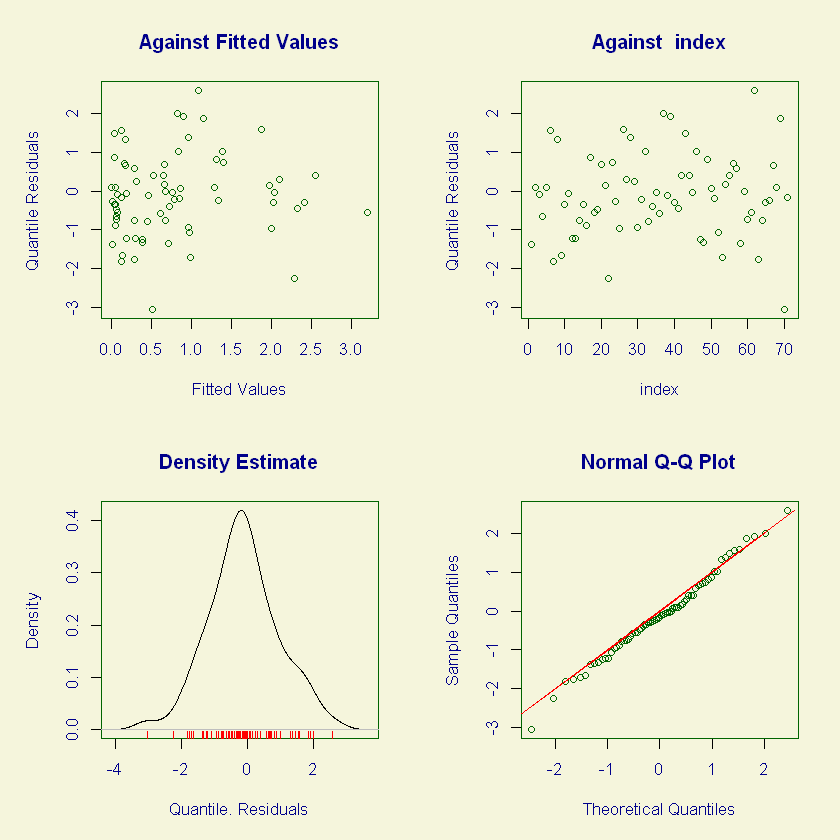

In [15]:
plot(fit2.nasal)

O comportamento é o mesmo do `fit1.nasal`: resíduos quantílicos sem tendência contra os ajustados e o índice, densidade simétrica e QQ-plot próximo da reta. Média ≈ 0 e variância ≈ 1.

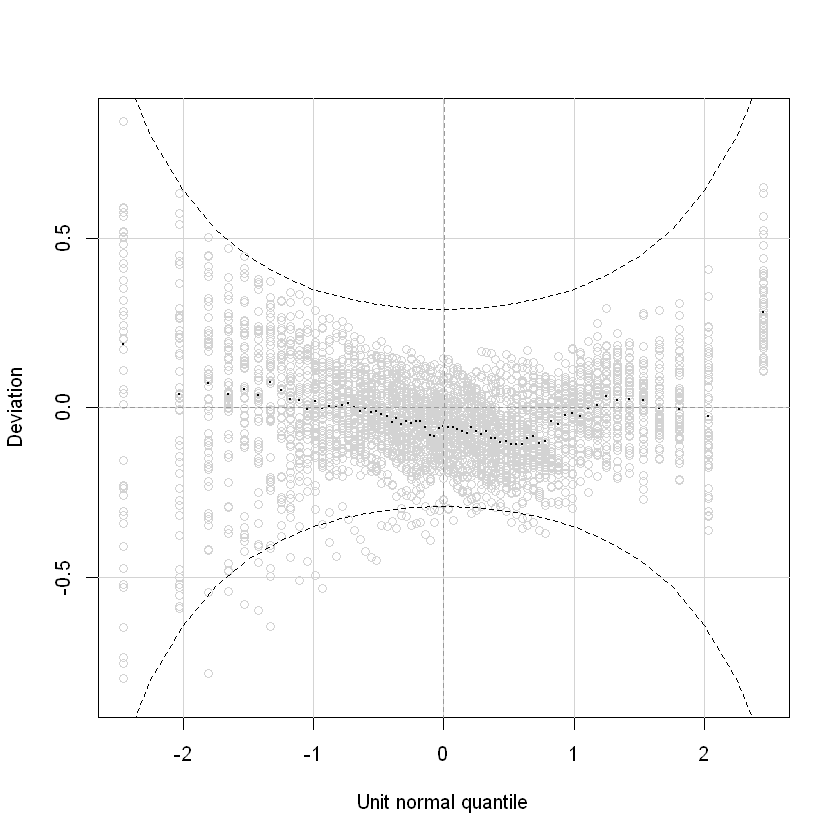

In [16]:
rqres.plot(fit2.nasal, howmany = 50, plot = "all")

As 50 realizações dos resíduos quantílicos seguem a reta do QQ-plot normal: **não há evidência contra a distribuição Poisson** no modelo agrupado.

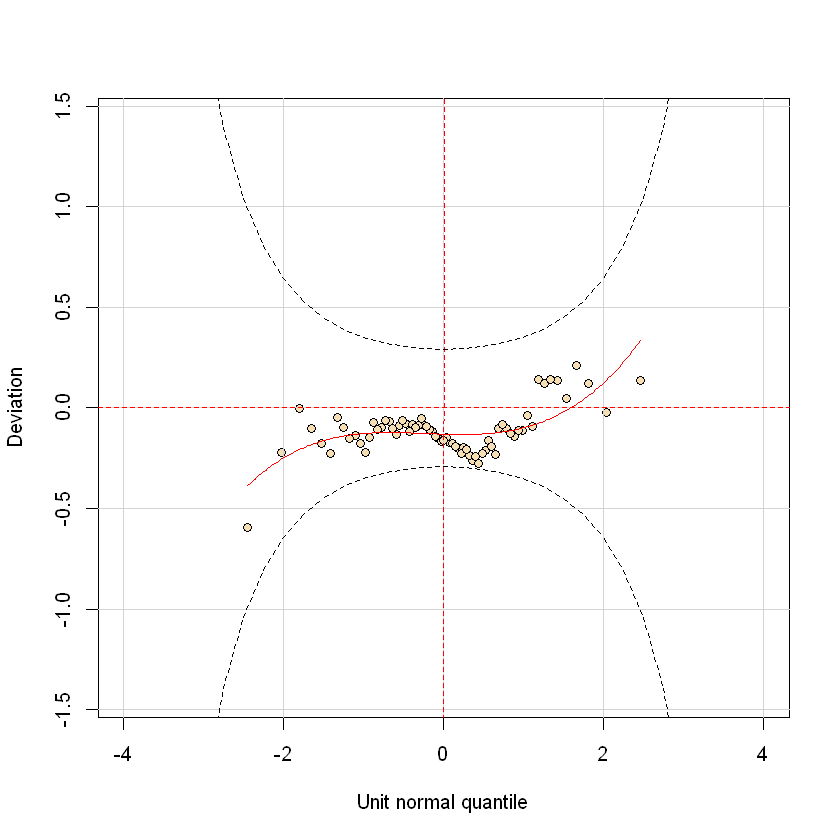

In [17]:
wp(fit2.nasal)

O *worm plot* fica dentro das bandas e sem forma sistemática: a média e a variância da Poisson estão adequadas.

Referência 2p/n = 0.197 


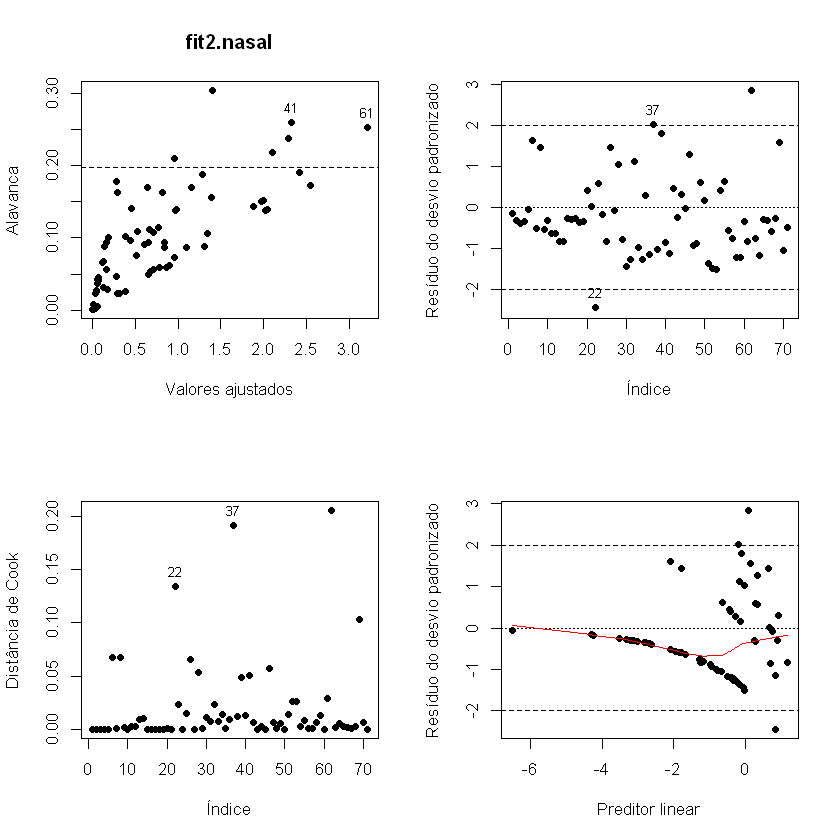

In [18]:
d2 <- diag_glm(fit2.glm, titulo = "fit2.nasal")

- **Alavanca:** referência $2p/n = 14/71 \approx 0{,}20$. As observações **23, 41 e 61** ficam acima (≈ 0,24–0,30), sem valores muito afastados.
- **Resíduos:** destaca-se a **obs. 62** ($t_D \approx 2{,}8$: idade 4, ano 2, tempo 3, com **5 casos em 56 pessoas-anos**, muito mais que o esperado), e depois 22 e 37 (≈ 2,5 e 2,0).
- **Cook:** os maiores valores são **62 e 37** (≈ 0,21 e 0,19), seguidos da 22.
- **Resíduo × preditor linear:** sem tendência.

Pontos fora do envelope: 0 de 71 (0.0%)


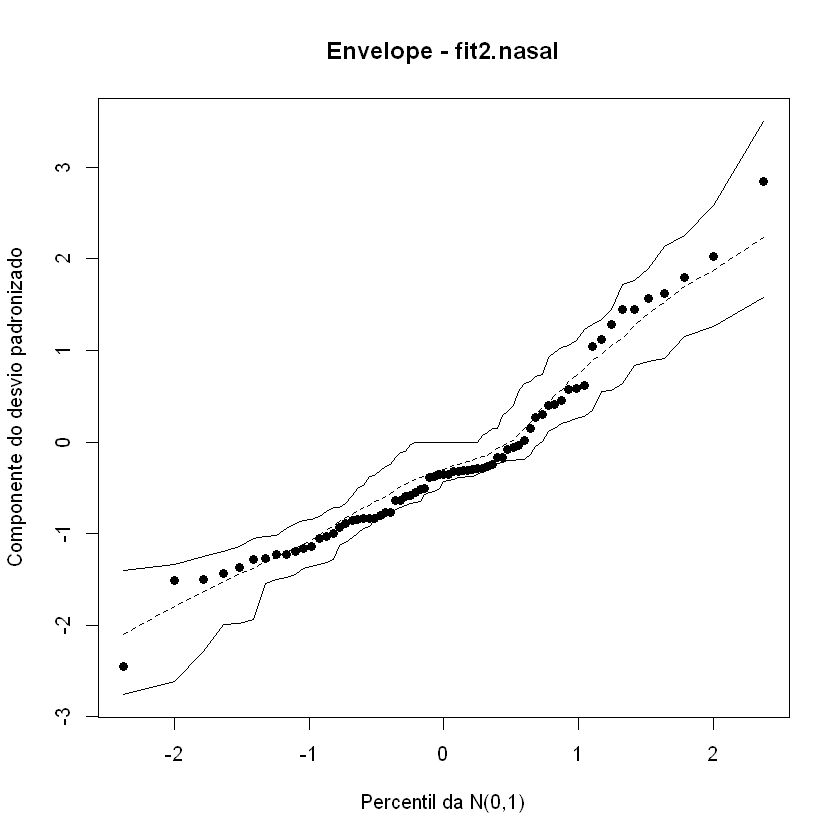

In [19]:
envelope_glm(fit2.glm, main = "Envelope - fit2.nasal")

Nenhum ponto fora do envelope: o modelo com os fatores agrupados está **bem ajustado**.

In [20]:
# sensibilidade: retirar uma de cada vez as observações destacadas (62, 37, 22)
for (k in c(62, 37, 22)) {
  ajk <- glm(casos ~ idade + nano + ntempo + offset(log(panos)), family = poisson, data = nasal, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(fit2.glm)) / coef(fit2.glm) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 3))
}


Sem a observação 62 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)     0.549   0.000
idade2         -0.196   0.023
idade3          0.016   0.001
idade4        -10.736   0.000
nano1920-1924  -7.561   0.000
ntempo40-49,9   7.937   0.028
ntempo50+       2.504   0.051

Sem a observação 37 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)    -1.264   0.000
idade2         -7.094   0.036
idade3          0.496   0.001
idade4         -0.349   0.000
nano1920-1924  18.802   0.000
ntempo40-49,9 -32.860   0.210
ntempo50+       1.978   0.052

Sem a observação 22 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)     0.623   0.000
idade2          8.220   0.014
idade3          0.017   0.001
idade4          1.089   0.000
nano1920-1924   2.636   0.000
ntempo40-49,9  27.684   0.008
ntempo50+      -4.389   0.067


- **Sem a 62:** idade e ano mudam menos de 11%; os efeitos de `ntempo` variam ≈ 8% e nada muda de significância.
- **Sem a 37:** o efeito de **ntempo 40-49,9** cai ≈ 33% e **deixa de ser significativo** (p ≈ 0,21); os demais mudam pouco.
- **Sem a 22:** o mesmo efeito aumenta ≈ 28% (p ≈ 0,008).

Portanto o efeito do tempo de 40–49,9 anos é o mais sensível a pontos individuais (é estimado com poucos casos). Idade e ano do primeiro emprego são estáveis. Como nenhuma observação parece erro de registro, mantemos todas.

## 1.3 Interpretação: `term.plot` e razões de taxas

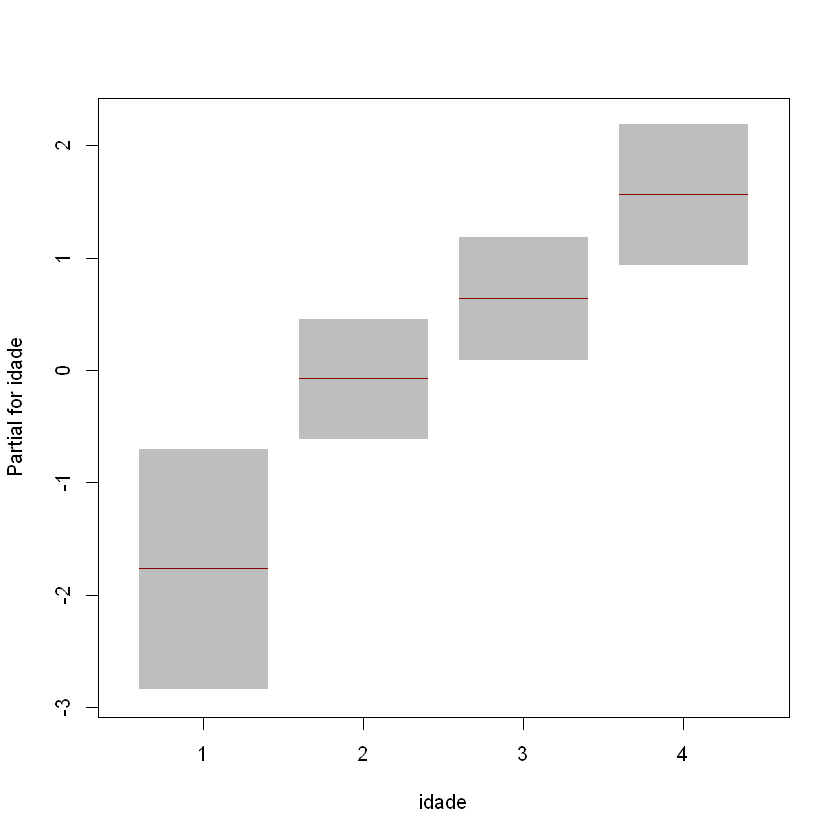

In [21]:
term.plot(fit2.nasal, terms = 1)

**Idade no primeiro emprego:** o efeito parcial (escala log) **cresce de forma monótona** do nível 1 ao nível 4. As bandas são largas no nível 1 (poucos casos nessa faixa), mas o crescimento é claro: quanto mais velho o trabalhador entrou na refinaria, maior a taxa de câncer nasal.

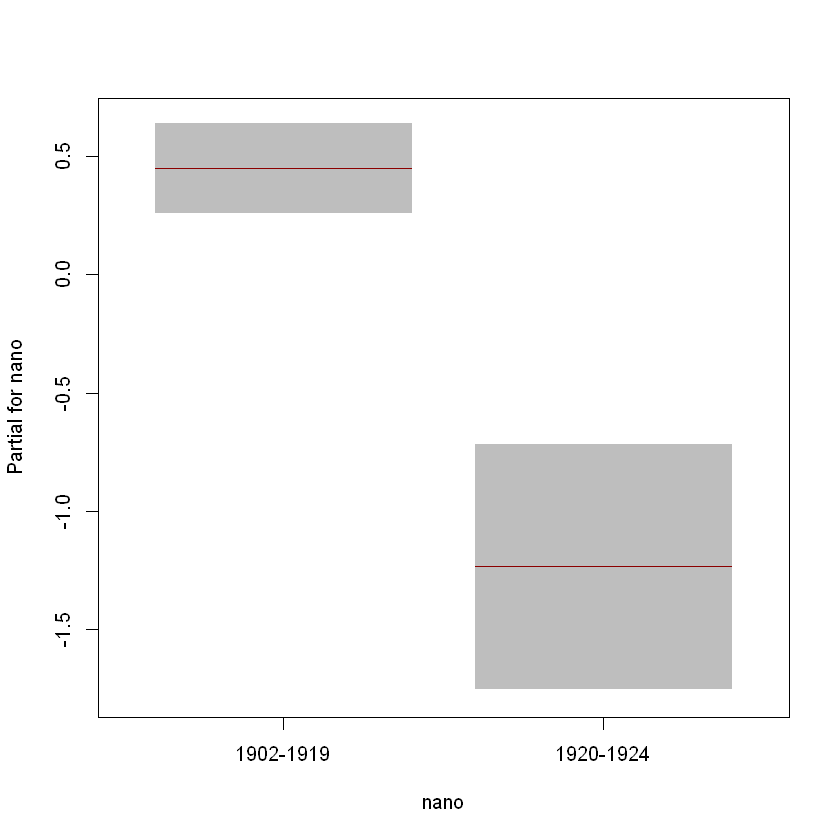

In [22]:
term.plot(fit2.nasal, terms = 2)

**Ano do primeiro emprego:** quem entrou em **1920–1924** tem efeito bem menor do que quem entrou em 1902–1919. Isso é coerente com melhorias nas condições de trabalho/processo da refinaria a partir dos anos 1920.

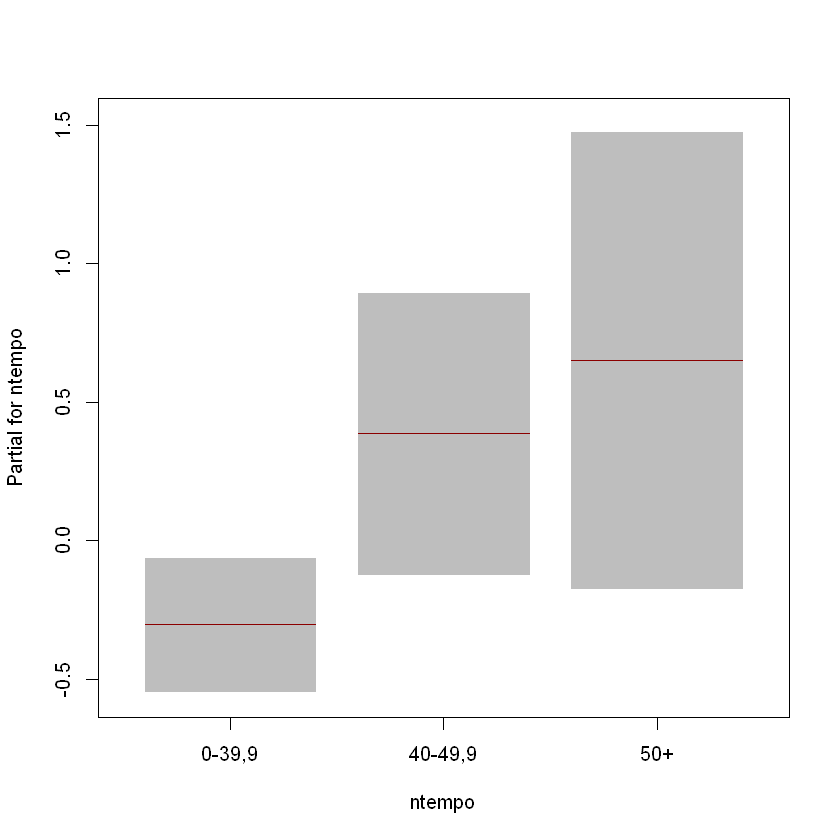

In [23]:
term.plot(fit2.nasal, terms = 3)

**Tempo desde o primeiro emprego:** o efeito aumenta de "0–39,9" para "40–49,9" e "50+", refletindo o longo período de latência do câncer nasal. As bandas de "40–49,9" e "50+" se sobrepõem bastante.

In [24]:
# razões de taxas (exp dos coeficientes) e IC de 95% de Wald
est <- coef(fit2.nasal)
ic  <- confint(fit2.nasal)
round(exp(cbind(RT = est, ic))[-1, ], 3)

,RT,2.5 %,97.5 %
idade2,5.438,1.266,23.359
idade3,11.078,2.541,48.295
idade4,27.998,6.137,127.734
nano1920-1924,0.186,0.093,0.371
"ntempo40-49,9",1.991,1.033,3.837
ntempo50+,2.595,0.975,6.907


Como a ligação é log com offset $\log(\text{panos})$, $e^{\beta}$ é a **razão de taxas** (RT) em relação ao nível de referência, com os outros fatores fixos:

| Comparação | RT | IC 95% |
|---|---|---|
| idade 2 vs 1 | 5,44 | (1,27; 23,4) |
| idade 3 vs 1 | 11,08 | (2,54; 48,3) |
| idade 4 vs 1 | 28,00 | (6,14; 127,7) |
| ano 1920–24 vs 1902–19 | 0,19 | (0,09; 0,37) |
| tempo 40–49,9 vs 0–39,9 | 1,99 | (1,03; 3,84) |
| tempo 50+ vs 0–39,9 | 2,60 | (0,98; 6,91) |

- **Idade:** quem entrou no nível 4 de idade tem taxa estimada **28 vezes** maior do que quem entrou no nível 1 (os ICs são largos porque o nível 1 tem só 2 casos).
- **Ano:** quem entrou em 1920–1924 tem taxa ≈ **81% menor** ($1 - 0{,}19$) que quem entrou em 1902–1919.
- **Tempo:** com 40–49,9 anos desde o primeiro emprego a taxa é ≈ **2 vezes** a de quem tem menos de 40 anos; com 50 anos ou mais, ≈ 2,6 vezes (IC inclui 1, marginal).

In [25]:
# razão de taxas entre os níveis 50+ e 40-49,9 de ntempo
fit2b.glm <- glm(casos ~ idade + nano + relevel(ntempo, ref = "40-49,9") + offset(log(panos)),
                 family = poisson, data = nasal)
round(exp(cbind(RT = coef(fit2b.glm), confint.default(fit2b.glm)))[7, ], 3)

RT  2.5 % 97.5 % 
 1.304  0.460  3.698

Trocando a referência de `ntempo` para "40-49,9", a RT de "50+" contra "40-49,9" é ≈ 1,30 com IC de 95% incluindo 1: **não há diferença significativa entre 40–49,9 e 50+ anos**. Esses dois níveis poderiam ainda ser agrupados, mas mantemos o agrupamento sugerido no enunciado.

---
# Exercício 2 — Nitrofen (Cap. 5, Ex. 22)

50 *C. dubia* expostos a 5 doses do herbicida Nitrofen (0, 80, 160, 235 e 310 mg/l), 10 animais por dose. Resposta: total de ovos eclodidos após 3 ninhadas (`tovos`). Para os coeficientes ficarem em escala razoável usamos `d = dose/100` (centenas de mg/l).

In [26]:
nit <- read.table(paste0(caminho, "L4-Q2-C5-EX22-nitrofen.txt"), header = TRUE)
nit$d <- nit$dose / 100
str(nit)
aggregate(tovos ~ dose, data = nit, FUN = function(x) c(media = mean(x), variancia = var(x)))

'data.frame':	50 obs. of  3 variables:
 $ dose : int  0 0 0 0 0 0 0 0 0 0 ...
 $ tovos: int  37 32 34 33 36 34 33 30 24 31 ...
 $ d    : num  0 0 0 0 0 0 0 0 0 0 ...


dose,tovos
<int>,"<dbl[,2]>"
0,"32.4, 13.155556"
80,"31.5, 10.722222"
160,"28.3, 5.566667"
235,"17.2, 34.844444"
310,"6.0, 13.777778"


Médias por dose: 32,4; 31,5; 28,3; 17,2; 6,0. A média **cai pouco até 160 mg/l e despenca depois**. As variâncias amostrais (13,2; 10,7; 5,6; 34,8; 13,8) ficam **abaixo ou perto das médias** nas doses baixas (subdispersão) e acima na dose 235; no geral não há sinal forte de sobredispersão.

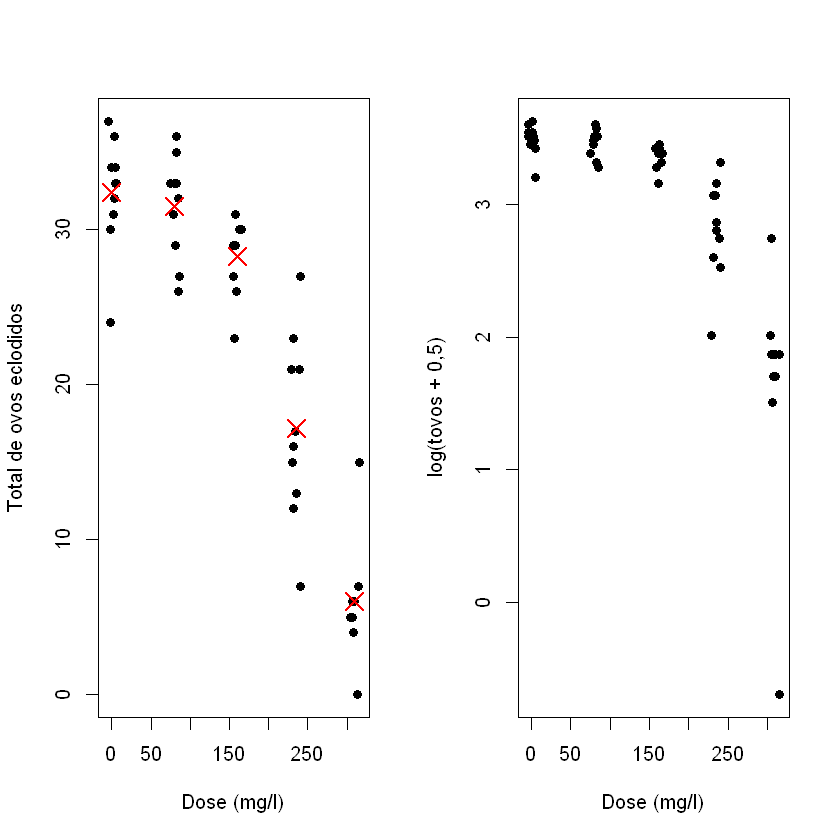

In [27]:
par(mfrow = c(1, 2))
plot(jitter(nit$dose, 0.4), nit$tovos, xlab = "Dose (mg/l)", ylab = "Total de ovos eclodidos", pch = 16)
points(sort(unique(nit$dose)), tapply(nit$tovos, nit$dose, mean), col = "red", pch = 4, cex = 2, lwd = 2)
plot(jitter(nit$dose, 0.4), log(nit$tovos + 0.5), xlab = "Dose (mg/l)", ylab = "log(tovos + 0,5)", pch = 16)
par(mfrow = c(1, 1))

O diagrama de dispersão (esquerda; × vermelho = média) mostra uma relação **não linear decrescente**: quase plana entre 0 e 160 mg/l e com queda acentuada a partir de 235 mg/l. Na escala log (direita) a curva continua **côncava**, portanto um modelo log-linear só com a dose (linear) não deve bastar; um termo quadrático é um candidato natural. Há um animal com 0 ovos na dose 310 que deve aparecer como resíduo grande.

## 2.1 Comparação de modelos Poisson

Modelos ajustados:

| Modelo | Ligação | Preditor |
|---|---|---|
| M1 | log | $\beta_0 + \beta_1 d$ |
| M2 | log | $\beta_0 + \beta_1 d + \beta_2 d^2$ |
| M3 | log | $\beta_0 + \beta_1 d + \beta_2 d^2 + \beta_3 d^3$ |
| M4 | log | dose como fator (modelo "saturado nas doses") |
| M5 | identidade | $\beta_0 + \beta_1 d$ |
| M6 | raiz quadrada | $\beta_0 + \beta_1 d + \beta_2 d^2$ |

In [28]:
m1 <- glm(tovos ~ d, family = poisson, data = nit)
m2 <- glm(tovos ~ d + I(d^2), family = poisson, data = nit)
m3 <- glm(tovos ~ d + I(d^2) + I(d^3), family = poisson, data = nit)
m4 <- glm(tovos ~ factor(dose), family = poisson, data = nit)
m5 <- glm(tovos ~ d, family = poisson(link = "identity"), data = nit, start = c(35, -8))
m6 <- glm(tovos ~ d + I(d^2), family = poisson(link = "sqrt"), data = nit)
modelos <- list(M1 = m1, M2 = m2, M3 = m3, M4 = m4, M5 = m5, M6 = m6)
data.frame(ligacao = sapply(modelos, function(m) m$family$link),
           p = sapply(modelos, function(m) length(coef(m))),
           desvio = round(sapply(modelos, deviance), 2),
           gl = sapply(modelos, df.residual),
           AIC = round(sapply(modelos, AIC), 2))

,ligacao,p,desvio,gl,AIC
,<chr>,<int>,<dbl>,<int>,<dbl>
M1,log,2,123.93,48,365.33
M2,log,3,56.61,47,300.02
M3,log,4,50.77,46,296.18
M4,log,5,50.70,45,298.11
M5,identity,2,81.14,48,322.55
M6,sqrt,3,52.03,47,295.44


- **M1 (log, linear)** é claramente ruim: desvio 123,9 com 48 g.l., AIC 365.
- **M5 (identidade, linear)** melhora (AIC 322,6) mas ainda tem desvio alto (81,1).
- **M2 (log, quadrático)** cai para desvio 56,6 (47 g.l.) e AIC 300,0.
- **M3 (cúbico)**, **M4 (fator)** e **M6 (raiz, quadrático)** têm AIC um pouco menores (296,2; 298,1; 295,4).

In [29]:
anova(m1, m2, m3, test = "Chisq")
anova(m2, m4, test = "Chisq")

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,48,123.92908,NA,NA,NA
2,47,56.60992,1,67.319154,2.309270e-16
3,46,50.77449,1,5.835431,1.570656e-02


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,47,56.60992,NA,NA,NA
2,45,50.70027,2,5.909656,0.05208763


- O termo quadrático é **altamente significativo** (queda de 67 no desvio, p ≈ 2e−16).
- O cúbico também é significativo a 5% (p ≈ 0,016).
- Contra o modelo com dose como fator (M4), o quadrático **não é rejeitado a 5%** (diferença 5,9 com 2 g.l., p ≈ 0,052): a curva quadrática descreve bem as 5 médias.

Os desvios de M2 (56,6 com 47 g.l., razão ≈ 1,2) e M4 (50,7 com 45 g.l.) indicam que **não há sobredispersão relevante**, então o Poisson é adequado. Vamos decidir entre os candidatos pelos diagnósticos.

Pontos fora do envelope: 38 de 50 (76.0%)
Pontos fora do envelope: 3 de 50 (6.0%)
Pontos fora do envelope: 5 de 50 (10.0%)
Pontos fora do envelope: 8 de 50 (16.0%)
Pontos fora do envelope: 6 de 50 (12.0%)
Pontos fora do envelope: 3 de 50 (6.0%)


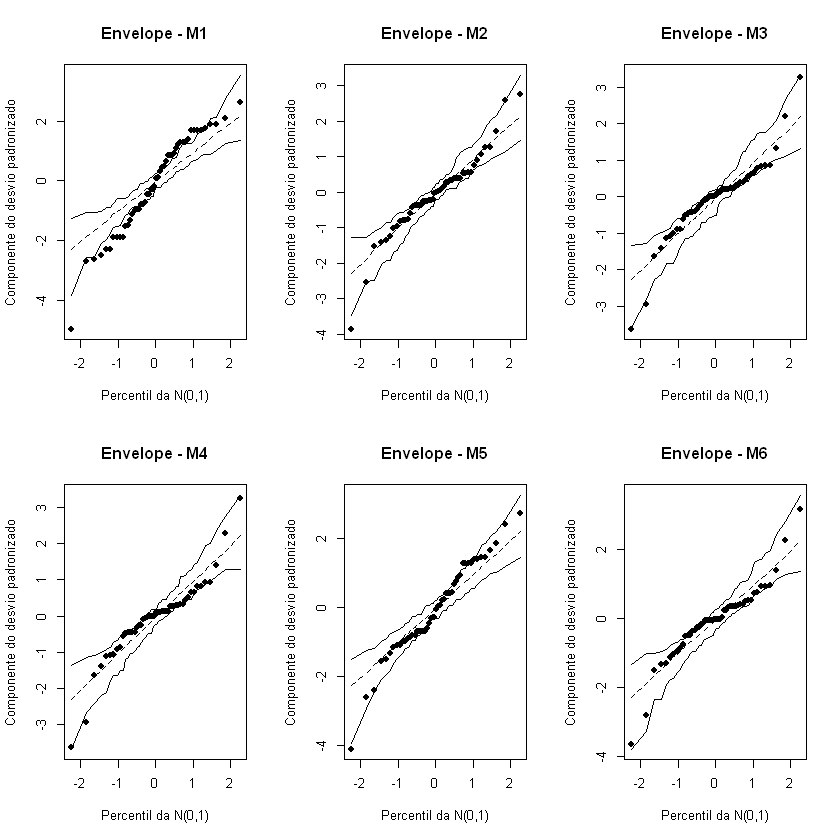

In [30]:
par(mfrow = c(2, 3))
for (nm in names(modelos)) envelope_glm(modelos[[nm]], main = paste("Envelope -", nm))
par(mfrow = c(1, 1))

Pontos fora do envelope (de 50): **M1: 38**, M2: 3, M3: 5, M4: 8, M5: 6, M6: 3.

- **M1** está muito mal ajustado (a maior parte dos pontos fora, com a forma de S típica de preditor mal especificado).
- **M2** e **M6** têm apenas 3 pontos fora (6%), praticamente só nas caudas: o mais extremo é o animal com **0 ovos na dose 310** (obs. 44).
- M3 e M4, apesar de AIC ligeiramente menores, não ficam melhores no envelope.
- M5 (identidade) tem 6 pontos fora (12%) e desvio e AIC bem piores que M2.

**Modelo escolhido: M2 (Poisson, ligação log, dose quadrática).** Tem AIC próximo dos melhores, envelope bom, não é rejeitado contra o modelo com dose como fator e, com ligação log, os coeficientes têm interpretação multiplicativa simples. (M6 é praticamente equivalente nos diagnósticos, mas a ligação raiz é mais difícil de interpretar.)

Referência 2p/n = 0.12 


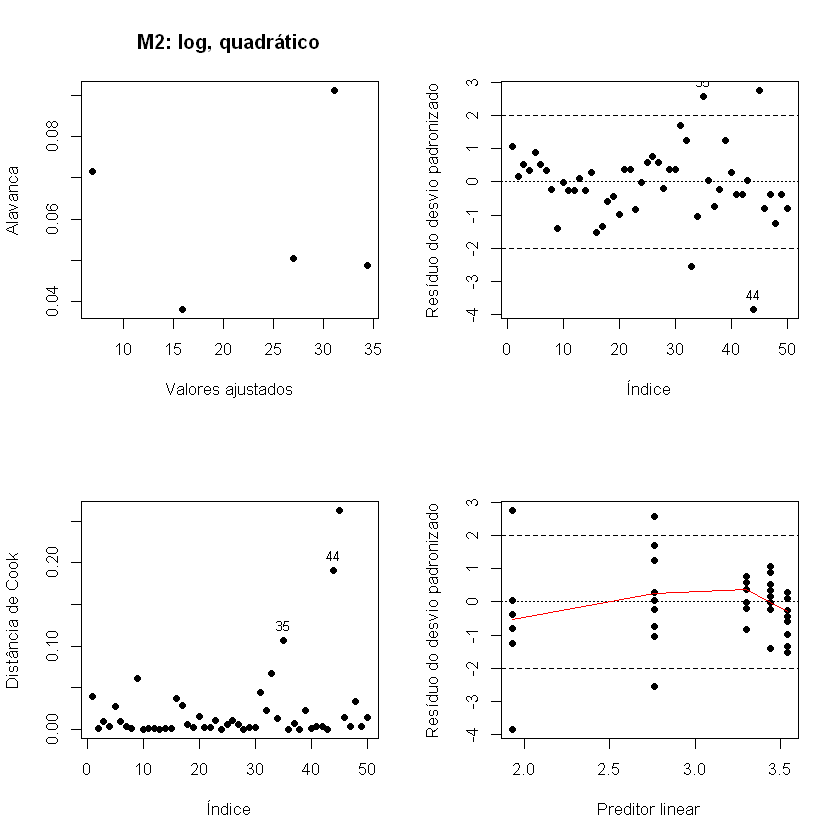

In [31]:
dm2 <- diag_glm(m2, titulo = "M2: log, quadrático")

- **Alavanca:** referência $2p/n = 6/50 = 0{,}12$. Todas abaixo (máximo ≈ 0,09, na dose 0, extremo do intervalo de dose).
- **Resíduos:** a **obs. 44** (dose 310, 0 ovos) tem $t_D \approx -3{,}9$; as obs. 45, 35 e 33 ficam perto de ±2,6. São animais com muito mais ou muito menos ovos do que o esperado para a dose.
- **Cook:** **45 e 44** se destacam (≈ 0,26 e 0,19).
- **Resíduo × preditor:** sem tendência (a curvatura de M1 desaparece).

In [32]:
for (k in c(44, 45)) {
  ajk <- glm(tovos ~ d + I(d^2), family = poisson, data = nit, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(m2)) / coef(m2) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 4))
}
nit[c(44, 45), ]


Sem a observação 44 - variação % das estimativas e p-valores:
             var_pct p_valor
(Intercept)   0.1604  0.0000
d           -10.0133  0.0013
I(d^2)       -6.8158  0.0000

Sem a observação 45 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept) -0.1997   0e+00
d           12.4033   1e-04
I(d^2)       8.4747   0e+00


,dose,tovos,d
,<int>,<int>,<dbl>
44,310,0,3.1
45,310,15,3.1


A obs. 44 (0 ovos) e a 45 (15 ovos, bem acima da média de 6 da dose 310) puxam os coeficientes em sentidos opostos (variações de ≈ 10% e ≈ 12% no coeficiente linear), mas a retirada de qualquer uma muda pouco a forma da curva e **nenhum coeficiente perde significância**. São valores plausíveis (um animal pode não ter ovos eclodidos), então mantemos todas as observações.

## 2.2 Interpretação do modelo selecionado

In [33]:
summary(m2)
exp(coef(m2))
dose_pico <- -coef(m2)[2] / (2 * coef(m2)[3]) * 100
cat("Dose em que a média estimada é máxima:", round(dose_pico, 1), "mg/l\n")


Call:
glm(formula = tovos ~ d + I(d^2), family = poisson, data = nit)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  3.43947    0.05411  63.570  < 2e-16 ***
d            0.33552    0.09385   3.575  0.00035 ***
I(d^2)      -0.26506    0.03334  -7.950 1.87e-15 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 319.02  on 49  degrees of freedom
Residual deviance:  56.61  on 47  degrees of freedom
AIC: 300.02

Number of Fisher Scoring iterations: 4


(Intercept)           d      I(d^2) 
 31.1704440   1.3986611   0.7671618

Dose em que a média estimada é máxima: 63.3 mg/l


Modelo ajustado:
$$\log \hat\mu(d) = 3{,}439 + 0{,}336\,d - 0{,}265\,d^2,\qquad d = \text{dose}/100.$$

- **Intercepto:** $e^{3{,}439} \approx 31{,}2$ ovos é a média estimada **sem herbicida** (dose 0).
- Como há termo quadrático, o efeito da dose **não é constante**: a razão de médias entre $d+\Delta$ e $d$ é $\exp\{\Delta(\beta_1 + \beta_2(2d + \Delta))\}$.
- A parábola em $\log\mu$ tem máximo em $d = -\beta_1/(2\beta_2) \approx 0{,}63$, isto é, **≈ 63 mg/l**. Ou seja, doses baixas praticamente não prejudicam a eclosão (a estimativa até sobe levemente, efeito pequeno que pode ser artefato da forma quadrática), e a partir daí o número médio de ovos cai cada vez mais rápido.

,dose,media_obs,media_ajust,razao_vs_dose_anterior
,<dbl>,<dbl>,<dbl>,<dbl>
0,0,32.4,31.17,NA
80,80,31.5,34.41,1.104
160,160,28.3,27.05,0.786
235,235,17.2,15.87,0.586
310,310,6.0,6.91,0.435


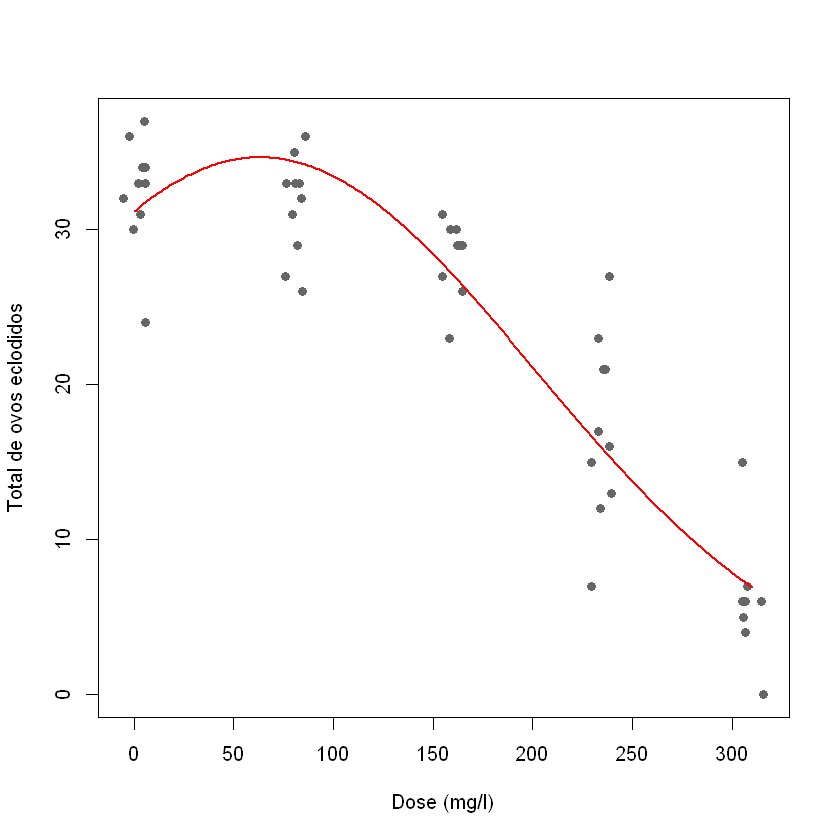

In [34]:
# médias estimadas e razões de médias entre doses consecutivas observadas
doses <- c(0, 80, 160, 235, 310)
mu_hat <- predict(m2, newdata = data.frame(d = doses / 100), type = "response")
data.frame(dose = doses, media_obs = tapply(nit$tovos, nit$dose, mean), media_ajust = round(mu_hat, 2),
           razao_vs_dose_anterior = round(c(NA, mu_hat[-1] / mu_hat[-5]), 3))

# curva ajustada sobre os dados
plot(jitter(nit$dose, 0.4), nit$tovos, xlab = "Dose (mg/l)", ylab = "Total de ovos eclodidos", pch = 16, col = "grey40")
dd <- seq(0, 310, 1)
lines(dd, predict(m2, newdata = data.frame(d = dd / 100), type = "response"), col = "red", lwd = 2)

Médias ajustadas (observadas): dose 0 → 31,2 (32,4); 80 → 34,4 (31,5); 160 → 27,1 (28,3); 235 → 15,9 (17,2); 310 → 6,9 (6,0). A curva vermelha acompanha bem os dados.

Razões entre doses consecutivas: 160 vs 80 → ≈ 0,79 (−21%); 235 vs 160 → ≈ 0,59 (−41%); 310 vs 235 → ≈ 0,44 (−56%). **Cada aumento de dose provoca uma redução proporcional cada vez maior** no número médio de ovos eclodidos: o Nitrofen tem efeito tóxico forte acima de ≈ 160 mg/l.

---
# Exercício 3 — Falhas em peças de tecido (Cap. 5, Ex. 7)

32 peças de tecido (Hinde, 1982): comprimento da peça (m) e número de falhas. O enunciado da lista dispensa o modelo de quase-verossimilhança.

In [35]:
rolos <- read.table(paste0(caminho, "L4-Q3-C5-EX7-rolos.txt"), header = TRUE)
str(rolos)
summary(rolos)
c(media_falhas = mean(rolos$falhas), var_falhas = var(rolos$falhas))

'data.frame':	32 obs. of  2 variables:
 $ comprimento: int  551 543 651 842 832 905 375 542 715 522 ...
 $ falhas     : int  6 8 4 9 17 23 9 9 14 6 ...


  comprimento        falhas      
 Min.   :122.0   Min.   : 1.000  
 1st Qu.:453.8   1st Qu.: 5.750  
 Median :590.5   Median : 8.000  
 Mean   :587.7   Mean   : 8.875  
 3rd Qu.:735.8   3rd Qu.: 9.250  
 Max.   :952.0   Max.   :28.000  

media_falhas   var_falhas 
     8.87500     33.79032

Comprimentos de 122 a 952 m e de 1 a 28 falhas. A variância das falhas (≈ 33,8) é bem maior que a média (≈ 8,9), mas isso também se deve ao efeito do comprimento; a sobredispersão precisa ser avaliada **condicionalmente** ao comprimento, no modelo.

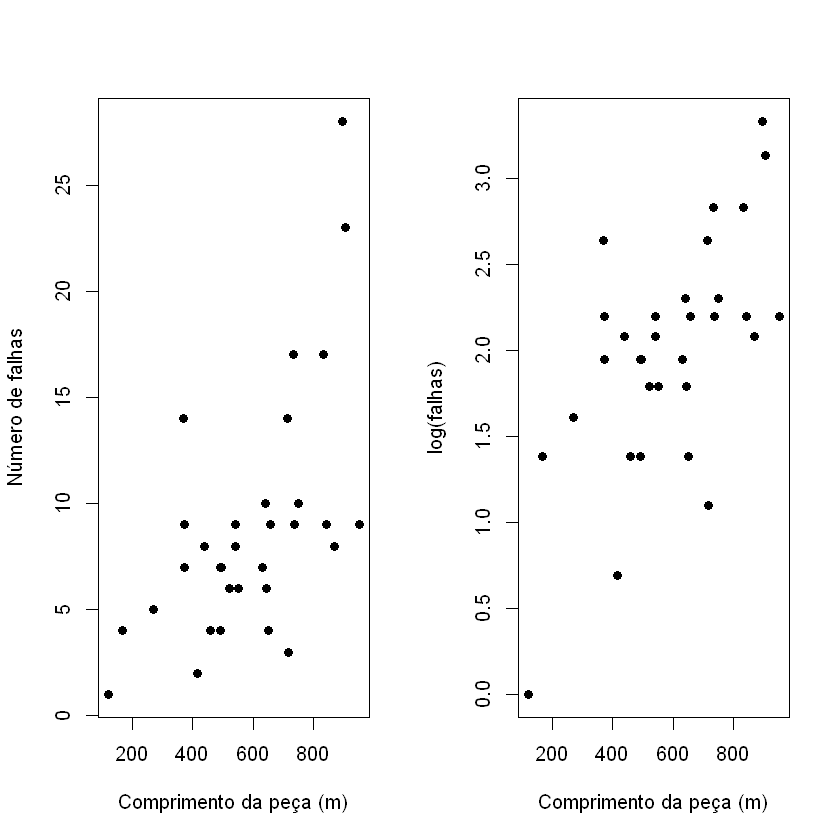

In [36]:
par(mfrow = c(1, 2))
plot(rolos$comprimento, rolos$falhas, xlab = "Comprimento da peça (m)", ylab = "Número de falhas", pch = 16)
plot(rolos$comprimento, log(rolos$falhas), xlab = "Comprimento da peça (m)", ylab = "log(falhas)", pch = 16)
par(mfrow = c(1, 1))

O número de falhas **aumenta com o comprimento**, e a **dispersão também cresce** com o comprimento (peças longas variam de 3 a 28 falhas). Na escala log a relação é aproximadamente linear. Isso sugere o modelo log-linear $\log\mu = \beta_0 + \beta_1 x$, com $x$ = comprimento, e já dá uma pista de variabilidade extra.

## 3.1 Modelo log-linear de Poisson

In [37]:
fit.p <- glm(falhas ~ comprimento, family = poisson, data = rolos)
summary(fit.p)

# alternativa: log(comprimento) como covariável
fit.p.log <- glm(falhas ~ log(comprimento), family = poisson, data = rolos)
c(AIC_linear = AIC(fit.p), AIC_logcomp = AIC(fit.p.log))


Call:
glm(formula = falhas ~ comprimento, family = poisson, data = rolos)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) 0.9717506  0.2124693   4.574 4.79e-06 ***
comprimento 0.0019297  0.0003063   6.300 2.97e-10 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 103.714  on 31  degrees of freedom
Residual deviance:  61.758  on 30  degrees of freedom
AIC: 189.06

Number of Fisher Scoring iterations: 4


AIC_linear AIC_logcomp 
   189.0559    191.8353

$\log\hat\mu = 0{,}972 + 0{,}00193\,x$, com o comprimento altamente significativo (p ≈ 3e−10). A alternativa com $\log(\text{comprimento})$ tem AIC ligeiramente pior (191,8 contra 189,1), então ficamos com o comprimento na escala original, que também é a escala pedida para interpretar $\mu(x+1)/\mu(x)$.

In [38]:
c(desvio = deviance(fit.p), gl = df.residual(fit.p),
  desvio_gl = deviance(fit.p) / df.residual(fit.p),
  pearson_gl = sum(residuals(fit.p, type = "pearson")^2) / df.residual(fit.p),
  p_valor = 1 - pchisq(deviance(fit.p), df.residual(fit.p)))

desvio           gl    desvio_gl   pearson_gl      p_valor 
6.175774e+01 3.000000e+01 2.058591e+00 2.121933e+00 5.610935e-04

**Indício de sobredispersão:** desvio = 61,8 com 30 g.l. → $D/\text{gl} \approx 2{,}06$, e a estatística de Pearson dá $X^2/\text{gl} \approx 2{,}12$. O teste do desvio rejeita o ajuste (p ≈ 0,0006). A variabilidade é cerca do **dobro** da que a Poisson admite.

Referência 2p/n = 0.125 


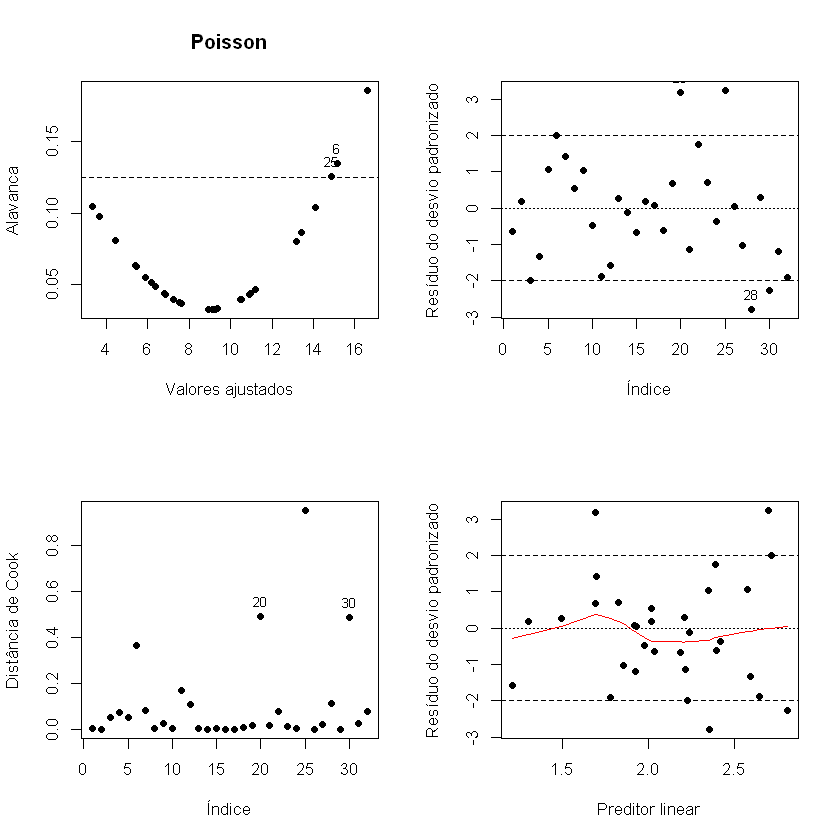

In [39]:
dp <- diag_glm(fit.p, titulo = "Poisson")

- **Alavanca:** referência $2p/n = 0{,}125$; obs. 30 (952 m) e 6 ficam um pouco acima, por serem as peças mais longas. Não preocupante.
- **Resíduos:** **várias** observações fora de ±2: **25, 20 e 28** ($t_D \approx 3{,}2$; $3{,}2$; $2{,}8$), além de 30 e 6. Para $n = 32$ esperaríamos cerca de 1 a 2 fora. A obs. 25 (895 m, 28 falhas) e a 20 (371 m, 14 falhas) têm muito mais falhas que o esperado.
- **Cook:** a **obs. 25** tem distância muito alta (≈ 0,95), seguida da 20 e da 30 (≈ 0,49).

Pontos fora do envelope: 3 de 32 (9.4%)


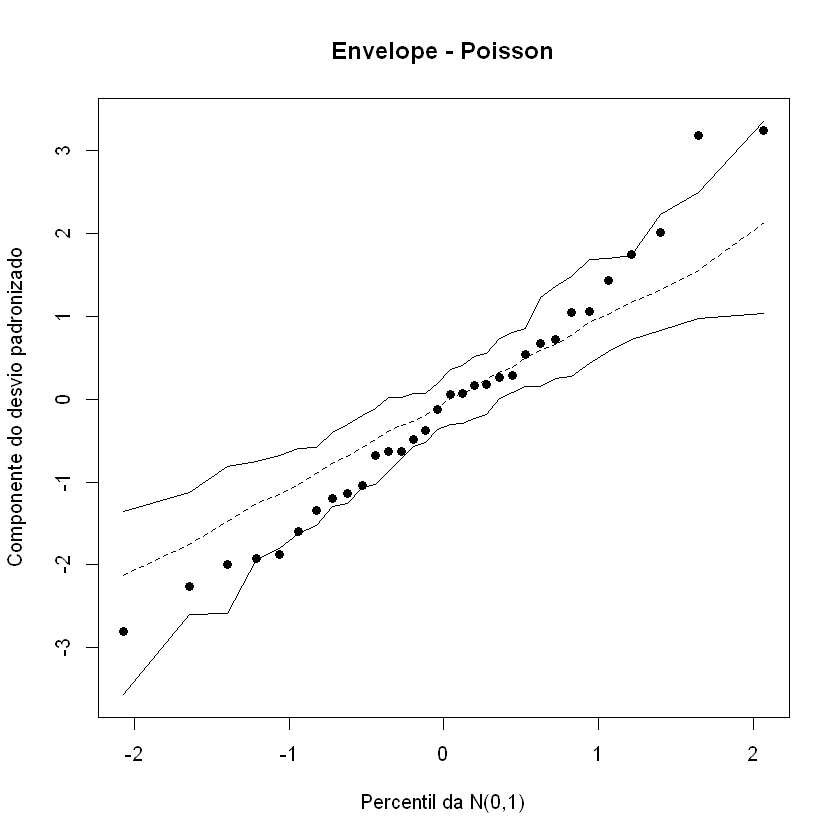

In [40]:
envelope_glm(fit.p, main = "Envelope - Poisson")

3 de 32 pontos (≈ 9%) fora do envelope, e o padrão dos resíduos é **mais espalhado** que as bandas nas duas caudas: sinal típico de **sobredispersão**. Juntando com $D/\text{gl} \approx 2$ e os vários resíduos grandes, concluímos que **há sobredispersão** e o modelo de Poisson não é adequado. Ajustamos a binomial negativa.

## 3.2 Modelo log-linear binomial negativo

$Y_i \sim BN(\mu_i, \nu)$ com $\text{Var}(Y_i) = \mu_i + \mu_i^2/\nu$ e $\log\mu_i = \beta_0 + \beta_1 x_i$.

In [41]:
fit.nb <- glm.nb(falhas ~ comprimento, data = rolos)
summary(fit.nb)
c(AIC_Poisson = AIC(fit.p), AIC_BN = AIC(fit.nb))

# teste da razão de verossimilhanças Poisson x BN (H0: 1/nu = 0, na fronteira -> p-valor/2)
LR <- as.numeric(2 * (logLik(fit.nb) - logLik(fit.p)))
c(LR = LR, p_valor = 0.5 * (1 - pchisq(LR, 1)))


Call:
glm.nb(formula = falhas ~ comprimento, data = rolos, init.theta = 9.56973877, 
    link = log)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) 1.0014663  0.2783655   3.598 0.000321 ***
comprimento 0.0018827  0.0004214   4.468  7.9e-06 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Negative Binomial(9.5697) family taken to be 1)

    Null deviance: 52.732  on 31  degrees of freedom
Residual deviance: 31.307  on 30  degrees of freedom
AIC: 180.55

Number of Fisher Scoring iterations: 1


              Theta:  9.57 
          Std. Err.:  4.89 

 2 x log-likelihood:  -174.554 

AIC_Poisson      AIC_BN 
   189.0559    180.5537

LR      p_valor 
1.050213e+01 5.961856e-04

- $\log\hat\mu = 1{,}001 + 0{,}00188\,x$; o coeficiente do comprimento quase não muda em relação ao Poisson (0,00193), mas o **erro-padrão aumenta** (de 0,00031 para 0,00042), refletindo corretamente a variabilidade extra. Continua altamente significativo (p ≈ 8e−6).
- $\hat\nu \approx 9{,}6$ (EP ≈ 4,9), então $\text{Var}(Y) \approx \mu + \mu^2/9{,}6$.
- Desvio = 31,3 com 30 g.l. (razão ≈ 1,04): **sem sobredispersão residual**.
- AIC cai de **189,1 (Poisson) para 180,6 (BN)**, e o teste da razão de verossimilhanças (LR ≈ 10,5, p ≈ 0,0006) **rejeita o Poisson**.

Referência 2p/n = 0.125 


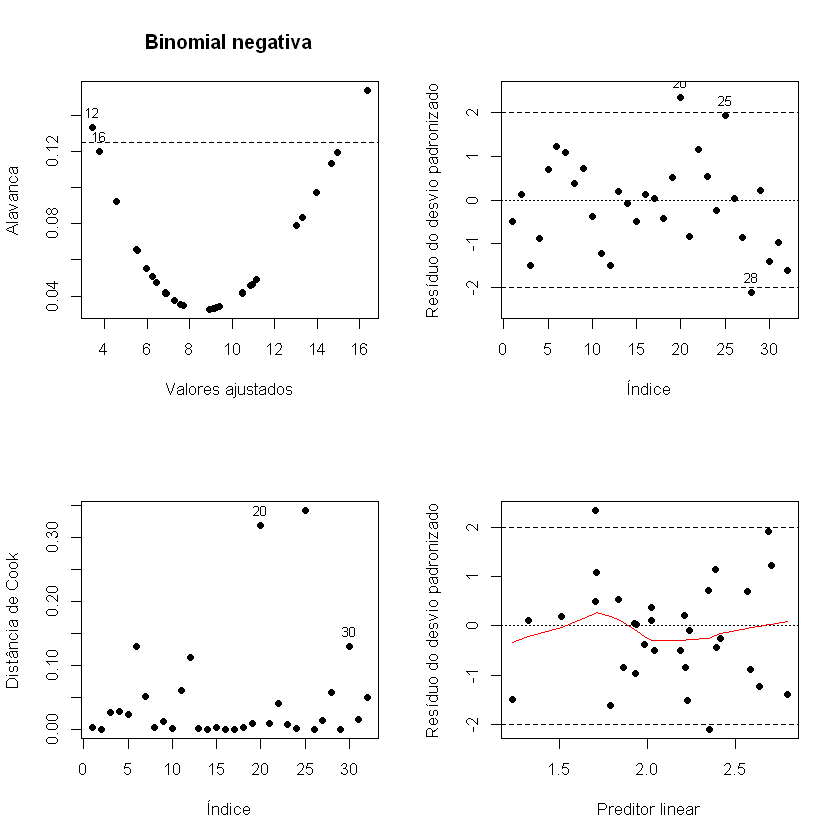

In [42]:
dnb <- diag_glm(fit.nb, titulo = "Binomial negativa")

- **Resíduos:** agora só **20 e 28** ficam pouco acima de 2 ($t_D \approx 2{,}3$ e $2{,}1$), o que é esperado em $n = 32$. A obs. 25, que tinha $t_D \approx 3{,}2$ no Poisson, cai para ≈ 1,9.
- **Cook:** os maiores são 25 e 20 (≈ 0,34 e 0,32), bem menores que os 0,95 do Poisson: a BN acomoda melhor as peças com muitas falhas.
- **Alavanca:** igual ao Poisson (30 e 6 um pouco acima de $2p/n$).

Pontos fora do envelope: 0 de 32 (0.0%)


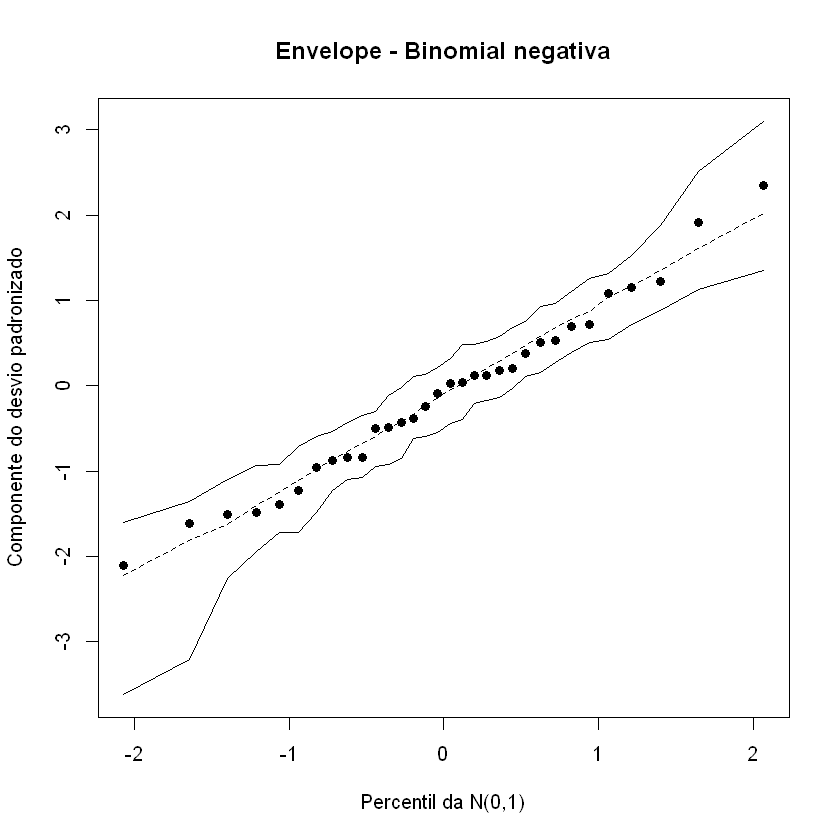

In [43]:
envelope_glm(fit.nb, main = "Envelope - Binomial negativa")

Com a binomial negativa **todos os pontos ficam dentro do envelope** (0 de 32). O modelo **binomial negativo está bem ajustado** e é o escolhido.

## 3.3 Interpretação: razão de médias $\mu(x+1)/\mu(x)$

In [44]:
# mu(x+1)/mu(x) = exp(beta1), por metro, e para 100 m
rm <- rbind(Poisson = c(coef(fit.p)[2], confint.default(fit.p)[2, ]),
            BN      = c(coef(fit.nb)[2], confint.default(fit.nb)[2, ]))
colnames(rm) <- c("beta1", "2,5%", "97,5%")
list(por_metro = round(exp(rm), 5), por_100m = round(exp(100 * rm), 3))

,beta1,"2,5%","97,5%"
Poisson,1.00193,1.00133,1.00253
BN,1.00188,1.00106,1.00271
,beta1,"2,5%","97,5%"
Poisson,1.213,1.142,1.288
BN,1.207,1.111,1.311


Com ligação log, $\mu(x+1)/\mu(x) = e^{\beta_1}$, que não depende de $x$:

- **BN:** $e^{0{,}00188} \approx 1{,}0019$: **cada metro a mais aumenta o número médio de falhas em ≈ 0,19%**.
- Como 1 metro é pouco, é mais útil olhar para **100 m**: $\mu(x+100)/\mu(x) = e^{100\beta_1} \approx 1{,}21$ (IC 95%: 1,11 a 1,31). **Cada 100 m a mais na peça aumenta o número médio de falhas em ≈ 21%.**
- O Poisson dá estimativa pontual parecida (1,21 por 100 m) mas com IC **artificialmente estreito** (1,14 a 1,29), por ignorar a sobredispersão.

---
# Exercício 4 — Germinação de sementes (Cap. 4, Ex. 10)

Número de sementes germinadas (`nsg`) em 100, segundo **temperatura da germinação** (`tempg`: 11°C, 21°C), **nível de umidade** (`umidade`: baixo, médio, alto) e **nível da temperatura** (`temp`: 21°C, 42°C, 62°C). Modelo logístico: $Y \sim \text{Bin}(100, \pi)$, $\text{logit}(\pi) = \mathbf{x}^\top\boldsymbol\beta$.

In [45]:
sem <- read.table(paste0(caminho, "L4-Q4-C4-EX10-sementes.txt"), header = TRUE)
sem$tempg   <- factor(sem$tempg)
sem$umidade <- factor(sem$umidade, levels = c("baixo", "medio", "alto"))
sem$temp    <- factor(sem$temp)
sem$m <- 100
sem

tempg,umidade,temp,nsg,m
<fct>,<fct>,<fct>,<int>,<dbl>
11,baixo,21,98,100
11,baixo,42,96,100
11,baixo,62,62,100
11,medio,21,94,100
11,medio,42,79,100
11,medio,62,3,100
11,alto,21,92,100
11,alto,42,41,100
11,alto,62,1,100


São 18 combinações (2 × 3 × 3), cada uma com 100 sementes. `umidade` foi ordenada como baixo → médio → alto, com "baixo" de referência. As referências dos outros fatores são `tempg` = 11°C e `temp` = 21°C.

, , tempg = 11

       temp
umidade 21 42 62
  baixo 98 96 62
  medio 94 79  3
  alto  92 41  1

, , tempg = 21

       temp
umidade 21 42 62
  baixo 94 93 65
  medio 94 71  2
  alto  91 30  1


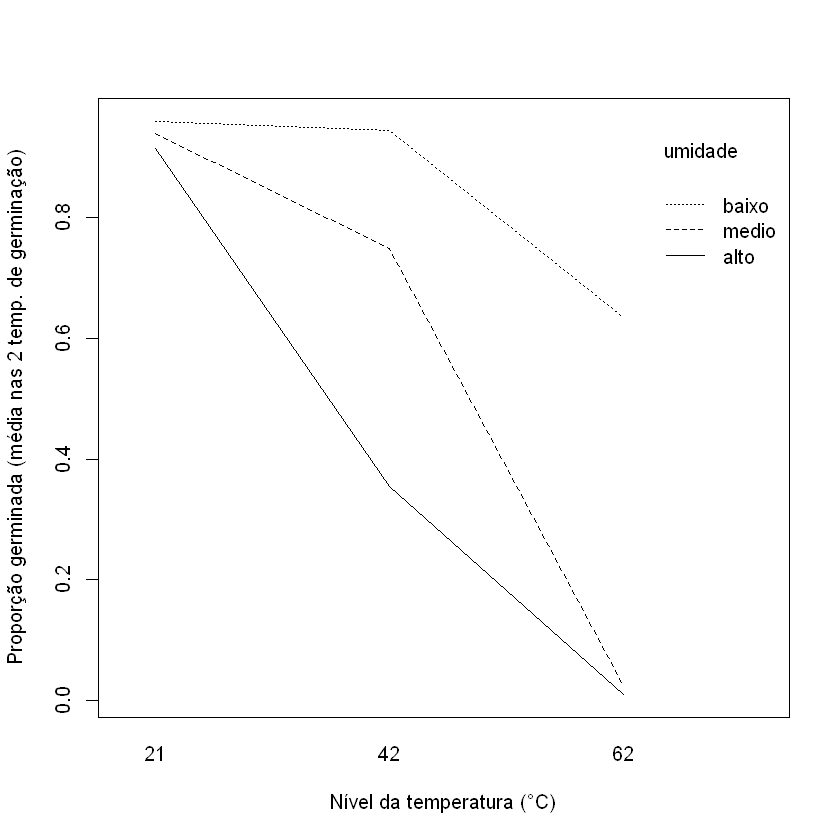

In [46]:
xtabs(nsg ~ umidade + temp + tempg, data = sem)
interaction.plot(sem$temp, sem$umidade, sem$nsg / 100, xlab = "Nível da temperatura (°C)",
                 ylab = "Proporção germinada (média nas 2 temp. de germinação)", trace.label = "umidade")

Com nível da temperatura de 21°C quase todas germinam (91–98%) qualquer que seja a umidade. Em 42°C a germinação cai muito com umidade alta (≈ 35%), e em 62°C só a umidade baixa ainda germina (≈ 63%), enquanto as umidades média e alta ficam perto de 0. As linhas **não são paralelas**: há forte sinal de **interação umidade × temperatura**. A temperatura da germinação (11°C vs 21°C) muda pouco.

## 4.1 Seleção por AIC com interações de 1ª ordem

In [47]:
fit0.sem <- glm(cbind(nsg, m - nsg) ~ tempg + umidade + temp, family = binomial, data = sem)
fit.sem <- stepAIC(fit0.sem,
                   scope = list(upper = ~ (tempg + umidade + temp)^2, lower = ~ 1),
                   direction = "both")

Start:  AIC=142.29
cbind(nsg, m - nsg) ~ tempg + umidade + temp

                Df Deviance     AIC
+ umidade:temp   4     4.43   91.53
<none>                63.19  142.29
- tempg          1    66.37  143.47
+ tempg:temp     2    60.51  143.61
+ tempg:umidade  2    62.95  146.05
- umidade        2   493.63  568.73
- temp           2   982.29 1057.40

Step:  AIC=91.53
cbind(nsg, m - nsg) ~ tempg + umidade + temp + umidade:temp

                Df Deviance     AIC
<none>                4.430  91.532
- tempg          1    7.880  92.983
+ tempg:temp     2    1.892  92.995
+ tempg:umidade  2    3.838  94.941
- umidade:temp   4   63.190 142.293


Partindo dos efeitos principais (AIC ≈ 142,3), o stepwise (nos dois sentidos) **inclui `umidade:temp`** (o AIC cai para ≈ 91,5). No passo seguinte nenhuma das interações com `tempg` reduz o AIC (≈ 93,0 e 94,9) e retirar `tempg` também aumenta o AIC (≈ 93,0), então o processo para.

**Modelo selecionado:** `tempg + umidade + temp + umidade:temp`.

In [48]:
summary(fit.sem)
c(desvio = deviance(fit.sem), gl = df.residual(fit.sem),
  p_valor = 1 - pchisq(deviance(fit.sem), df.residual(fit.sem)))
drop1(fit.sem, test = "Chisq")


Call:
glm(formula = cbind(nsg, m - nsg) ~ tempg + umidade + temp + 
    umidade:temp, family = binomial, data = sem)

Coefficients:
                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)           3.3251     0.3706   8.971  < 2e-16 ***
tempg21              -0.2765     0.1492  -1.853   0.0638 .  
umidademedio         -0.4269     0.4680  -0.912   0.3617    
umidadealto          -0.8026     0.4412  -1.819   0.0689 .  
temp42               -0.3345     0.4760  -0.703   0.4823    
temp62               -2.6305     0.3899  -6.747 1.51e-11 ***
umidademedio:temp42  -1.3220     0.5849  -2.260   0.0238 *  
umidadealto:temp42   -2.6496     0.5595  -4.736 2.18e-06 ***
umidademedio:temp62  -3.8020     0.6679  -5.693 1.25e-08 ***
umidadealto:temp62   -4.3581     0.8495  -5.130 2.89e-07 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1230.8604  on 17  degrees of freedom
Residual devia

desvio        gl   p_valor 
4.4297550 8.0000000 0.8164191

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,4.429755,91.53238,NA,NA
tempg,1,7.880214,92.98284,3.450459,6.323422e-02
umidade:temp,4,63.190319,142.29294,58.760564,5.283205e-12


- **Ajuste:** desvio = 4,43 com 8 g.l. (p ≈ 0,82): **ajuste muito bom** e sem sobredispersão.
- **Interação umidade × temp:** extremamente significativa (LRT = 58,8 com 4 g.l., p ≈ 5e−12).
- **tempg:** marginal (LRT = 3,45, p ≈ 0,063); o AIC o mantém no modelo.

## 4.2 Interpretação

In [49]:
# razão de chances da temperatura da germinação
round(exp(cbind(OR = coef(fit.sem), confint.default(fit.sem)))["tempg21", ], 3)

# probabilidades estimadas de germinação
grade <- expand.grid(tempg = levels(sem$tempg), umidade = levels(sem$umidade), temp = levels(sem$temp))
grade$p_hat <- round(predict(fit.sem, newdata = grade, type = "response"), 3)
xtabs(p_hat ~ umidade + temp + tempg, data = grade)

OR  2.5 % 97.5 % 
 0.758  0.566  1.016

, , tempg = 11

       temp
umidade    21    42    62
  baixo 0.965 0.952 0.667
  medio 0.948 0.776 0.028
  alto  0.926 0.387 0.011

, , tempg = 21

       temp
umidade    21    42    62
  baixo 0.955 0.938 0.603
  medio 0.932 0.724 0.022
  alto  0.904 0.323 0.009


- **Temperatura da germinação:** passar de 11°C para 21°C multiplica a **chance** de germinar por $e^{-0{,}277} \approx 0{,}76$ (IC 95%: 0,57 a 1,02), uma redução de ≈ 24%, que não é significativa a 5%. Como não há interação com `tempg`, esse efeito vale para qualquer combinação de umidade e temperatura.
- **Umidade × nível da temperatura:** o efeito de um fator depende do outro, por isso olhamos as probabilidades estimadas (tabela acima):
  - em **21°C** a germinação é alta (≈ 90–97%) e a umidade importa pouco;
  - em **42°C** a umidade alta derruba a germinação (de ≈ 95% com umidade baixa para ≈ 32–39% com umidade alta);
  - em **62°C** só a umidade baixa permite germinação razoável (≈ 60–67%); com umidade média ou alta a probabilidade fica perto de 0 (≈ 1–3%).

Em termos de chances, por exemplo: com 62°C, a chance de germinar com umidade alta é $e^{-0{,}803 - 4{,}358} \approx 0{,}006$ vezes a chance com umidade baixa, enquanto com 21°C essa razão é só $e^{-0{,}803} \approx 0{,}45$.

**Resumo:** para obter boa germinação, a semente deve ser mantida em temperatura baixa e/ou umidade baixa; a combinação de **temperatura e umidade altas é a pior**.

## 4.3 Análise de resíduos do modelo selecionado

Referência 2p/n = 1.111 


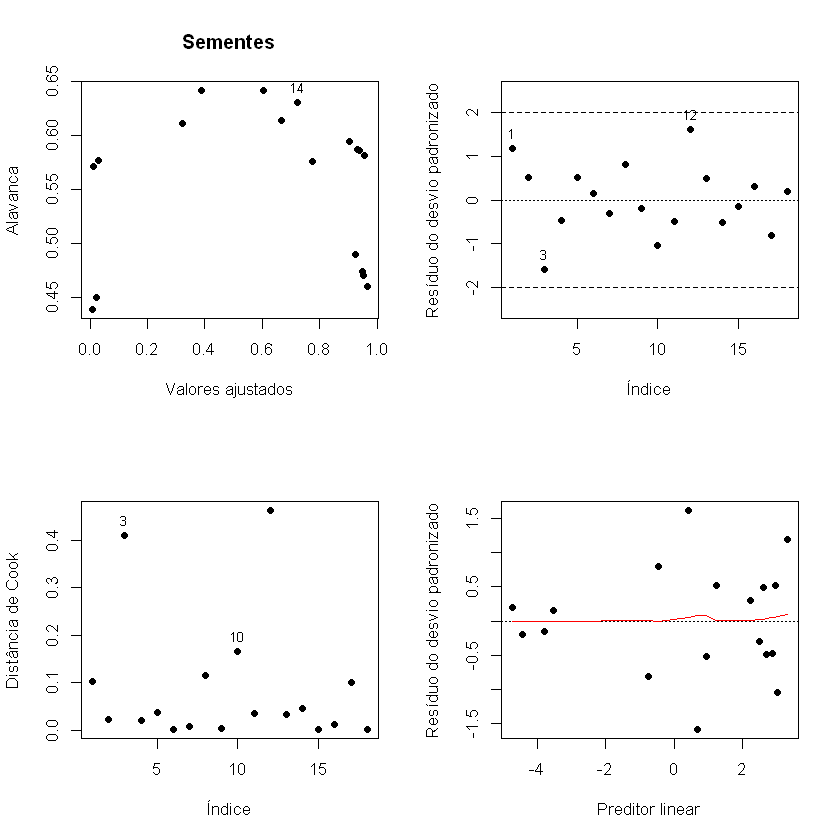

In [50]:
ds <- diag_glm(fit.sem, titulo = "Sementes")

- **Alavanca:** $p = 10$ e $n = 18$, então $2p/n \approx 1{,}11$ e todos os $h_{ii}$ (entre 0,44 e 0,64) ficam abaixo. Os valores são altos porque o modelo tem muitos parâmetros para 18 observações, não há um ponto isolado.
- **Resíduos:** todos dentro de ±2 (maiores: obs. 12 ≈ 1,6 e obs. 3 ≈ −1,6).
- **Cook:** as maiores são **12 e 3** (≈ 0,46 e 0,41), nada muito destoante.
- **Resíduo × preditor:** sem tendência.

Pontos fora do envelope: 0 de 18 (0.0%)


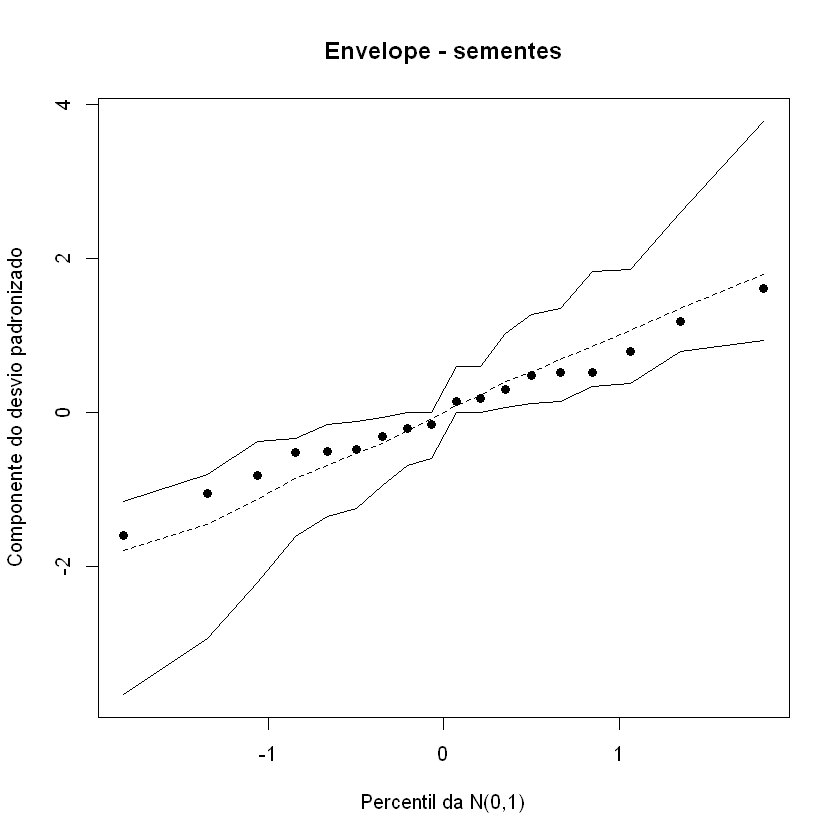

In [51]:
envelope_glm(fit.sem, main = "Envelope - sementes")

Nenhum ponto fora do envelope. Junto com o desvio baixo (4,4 em 8 g.l.), o **modelo logístico com interação umidade × temperatura está bem ajustado**.

---
# Exercício 5 — Leucemia (Cap. 4, Ex. 21)

51 pacientes com leucemia aguda. Resposta: `trat` (1 = tratamento satisfatório, 0 = não). Covariáveis pré-tratamento: `idade` (anos), `mancha` (%), `infil` (infiltração na medula, %), `cel` (células com leucemia na medula, %), `malig` (malignidade, ×10³) e `temp` (temperatura máxima, ×10 °F). `tempo` e `sobrev` são posteriores ao tratamento e não entram no modelo.

Modelo: $Y_i \sim \text{Bernoulli}(\pi_i)$, $\text{logit}(\pi_i) = \mathbf{x}_i^\top\boldsymbol\beta$. Seleção *stepwise* usando **AIC** (em vez de $P_E = P_S = 0{,}20$, como pede a lista).

In [52]:
# as duas primeiras linhas do arquivo estão em branco
leu <- read.table(paste0(caminho, "L4-Q5-C4-EX21-leuce.txt"), header = TRUE, skip = 2)
str(leu)
table(leu$trat)

'data.frame':	51 obs. of  9 variables:
 $ idade : int  20 25 26 26 27 27 28 28 31 33 ...
 $ mancha: int  78 64 61 64 95 80 88 70 72 58 ...
 $ infil : int  39 61 55 64 95 64 88 70 72 58 ...
 $ cel   : int  7 16 12 16 6 8 20 14 5 7 ...
 $ malig : num  0.6 35 7.5 21 7.5 0.6 4.8 10 2.3 5.7 ...
 $ temp  : int  990 1030 982 1000 980 1010 986 1010 988 986 ...
 $ trat  : int  1 1 1 1 1 0 1 1 1 0 ...
 $ tempo : int  18 31 31 31 36 1 9 39 20 4 ...
 $ sobrev: int  0 1 0 0 0 0 0 1 1 0 ...



 0  1 
27 24 

51 pacientes: 24 com tratamento satisfatório e 27 sem. O `skip = 2` pula as duas linhas em branco do início do arquivo (uma delas tem espaços, o que confunde o `read.table`).

,idade,mancha,infil,cel,malig,temp
idade,1.00,-0.20,-0.14,-0.12,0.05,0.08
mancha,-0.20,1.00,0.85,0.10,0.33,-0.03
infil,-0.14,0.85,1.00,0.14,0.34,-0.01
cel,-0.12,0.10,0.14,1.00,0.38,0.07
malig,0.05,0.33,0.34,0.38,1.00,0.36
temp,0.08,-0.03,-0.01,0.07,0.36,1.00


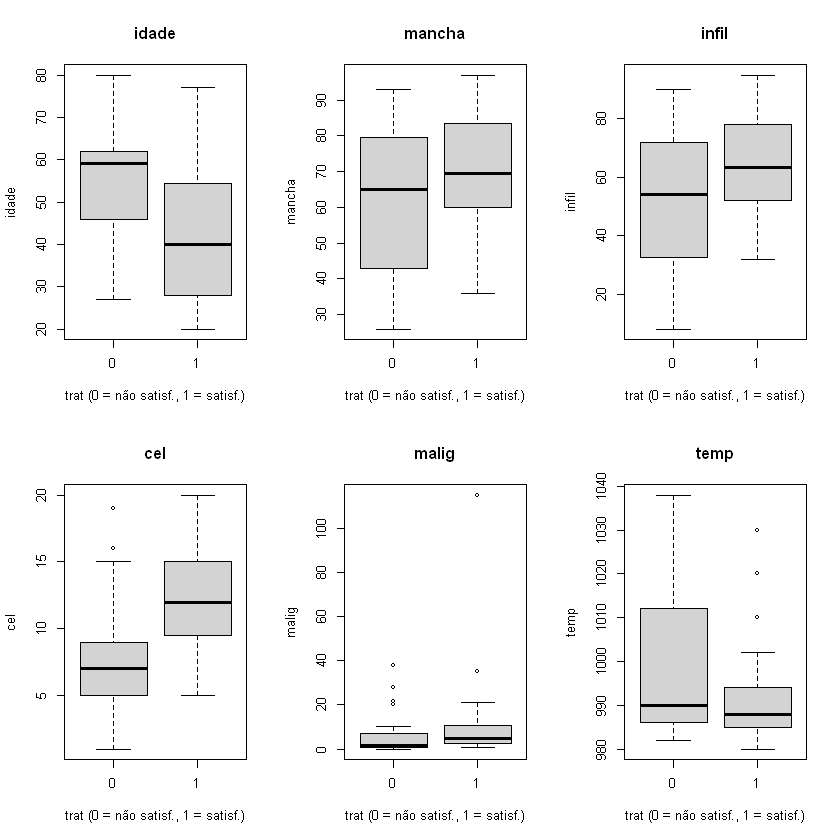

In [53]:
par(mfrow = c(2, 3))
for (v in c("idade", "mancha", "infil", "cel", "malig", "temp"))
  boxplot(leu[[v]] ~ leu$trat, xlab = "trat (0 = não satisf., 1 = satisf.)", ylab = v, main = v)
par(mfrow = c(1, 1))
round(cor(leu[, 1:6]), 2)

Descritivamente, os pacientes com tratamento satisfatório tendem a ser **mais jovens**, ter **mais células com leucemia** (`cel`) e **temperatura menor**. `malig` tem valores muito assimétricos (um paciente com 115). `mancha` e `infil` são fortemente correlacionadas (≈ 0,85), então é provável que só uma delas entre no modelo.

## 5.1 Stepwise por AIC: efeitos principais

In [54]:
nulo.leu <- glm(trat ~ 1, family = binomial, data = leu)
s1.leu <- stepAIC(nulo.leu, scope = list(upper = ~ idade + mancha + infil + cel + malig + temp, lower = ~ 1),
                  direction = "both")
summary(s1.leu)

Start:  AIC=72.52
trat ~ 1

         Df Deviance    AIC
+ cel     1   57.119 61.119
+ idade   1   64.004 68.004
+ temp    1   66.766 70.766
+ infil   1   66.849 70.849
+ mancha  1   68.117 72.117
+ malig   1   68.323 72.323
<none>        70.524 72.524

Step:  AIC=61.12
trat ~ cel

         Df Deviance    AIC
+ temp    1   49.645 55.645
+ idade   1   51.387 57.387
+ infil   1   54.158 60.158
+ mancha  1   54.980 60.980
<none>        57.119 61.119
+ malig   1   57.080 63.080
- cel     1   70.524 72.524

Step:  AIC=55.65
trat ~ cel + temp

         Df Deviance    AIC
+ idade   1   43.265 51.265
+ infil   1   46.438 54.438
+ mancha  1   46.835 54.835
+ malig   1   47.492 55.492
<none>        49.645 55.645
- temp    1   57.119 61.119
- cel     1   66.766 70.766

Step:  AIC=51.27
trat ~ cel + temp + idade

         Df Deviance    AIC
+ infil   1   40.136 50.136
+ malig   1   41.042 51.042
+ mancha  1   41.222 51.222
<none>        43.265 51.265
- idade   1   49.645 55.645
- temp    1   51.387


Call:
glm(formula = trat ~ cel + temp + idade + infil, family = binomial, 
    data = leu)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept) 95.56766   38.59482   2.476  0.01328 * 
cel          0.40673    0.13034   3.121  0.00181 **
temp        -0.09944    0.03954  -2.515  0.01191 * 
idade       -0.06026    0.02678  -2.250  0.02445 * 
infil        0.03413    0.02079   1.641  0.10077   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 40.136  on 46  degrees of freedom
AIC: 50.136

Number of Fisher Scoring iterations: 6


Partindo do modelo nulo, o stepwise inclui na ordem `cel`, `temp`, `idade` e `infil` e para (AIC ≈ 50,1). `mancha` e `malig` não entram. (Fazendo o stepwise a partir do modelo completo chega-se ao mesmo conjunto.) `cel`, `temp` e `idade` são significativas a 5% e `infil` tem p ≈ 0,10.

## 5.2 Stepwise por AIC: interações de primeira ordem

In [55]:
s2.leu <- stepAIC(s1.leu, scope = list(upper = ~ (idade + infil + cel + temp)^2, lower = ~ 1),
                  direction = "both")
summary(s2.leu)
anova(s1.leu, s2.leu, test = "Chisq")

Start:  AIC=50.14
trat ~ cel + temp + idade + infil

              Df Deviance    AIC
+ infil:temp   1   37.599 49.599
<none>             40.136 50.136
- infil        1   43.265 51.265
+ cel:temp     1   39.435 51.435
+ idade:infil  1   39.671 51.671
+ infil:cel    1   39.891 51.891
+ idade:cel    1   39.895 51.895
+ idade:temp   1   40.136 52.136
- idade        1   46.438 54.438
- temp         1   48.971 56.971
- cel          1   57.602 65.602

Step:  AIC=49.6
trat ~ cel + temp + idade + infil + temp:infil

              Df Deviance    AIC
+ idade:infil  1   35.462 49.462
<none>             37.599 49.599
- temp:infil   1   40.136 50.136
+ idade:temp   1   37.211 51.211
+ infil:cel    1   37.308 51.308
+ cel:temp     1   37.552 51.552
+ idade:cel    1   37.579 51.579
- idade        1   43.746 53.746
- cel          1   57.586 67.586

Step:  AIC=49.46
trat ~ cel + temp + idade + infil + temp:infil + idade:infil

              Df Deviance    AIC
<none>             35.462 49.462
- idade:in


Call:
glm(formula = trat ~ cel + temp + idade + infil + temp:infil + 
    idade:infil, family = binomial, data = leu)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)   
(Intercept) -1.640e+02  1.294e+02  -1.268   0.2050   
cel          6.156e-01  2.036e-01   3.024   0.0025 **
temp         1.671e-01  1.311e-01   1.274   0.2026   
idade       -2.109e-01  1.150e-01  -1.834   0.0666 . 
infil        4.516e+00  2.255e+00   2.003   0.0452 * 
temp:infil  -4.628e-03  2.305e-03  -2.008   0.0446 * 
idade:infil  2.386e-03  1.727e-03   1.382   0.1671   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 35.462  on 44  degrees of freedom
AIC: 49.462

Number of Fisher Scoring iterations: 6


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,46,40.13624,NA,NA,NA
2,44,35.46231,2,4.673929,0.09662047


Considerando as interações duas a duas entre as variáveis selecionadas, o AIC inclui `temp:infil` e `idade:infil`, mas o ganho é **muito pequeno**: AIC de 50,1 para 49,5 (diferença de 0,7, menor que 2). Além disso:

- `idade:infil` não é significativa (p ≈ 0,17);
- no modelo com interações o sinal de `temp` muda e os erros-padrão aumentam muito (intercepto ≈ −164 com EP 129), sinal de instabilidade com só 51 observações;
- o teste conjunto das duas interações **não rejeita** sua retirada (LRT = 4,67 com 2 g.l., p ≈ 0,097).

Como a diferença de AIC é desprezível e as interações deixam o modelo instável e difícil de interpretar, **adotamos o modelo só com efeitos principais**: `trat ~ idade + infil + cel + temp`.

In [56]:
fit.leu <- glm(trat ~ idade + infil + cel + temp, family = binomial, data = leu)
summary(fit.leu)


Call:
glm(formula = trat ~ idade + infil + cel + temp, family = binomial, 
    data = leu)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept) 95.56766   38.59482   2.476  0.01328 * 
idade       -0.06026    0.02678  -2.250  0.02445 * 
infil        0.03413    0.02079   1.641  0.10077   
cel          0.40673    0.13034   3.121  0.00181 **
temp        -0.09944    0.03954  -2.515  0.01191 * 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 40.136  on 46  degrees of freedom
AIC: 50.136

Number of Fisher Scoring iterations: 6


$$\text{logit}(\hat\pi) = 95{,}57 - 0{,}060\,\text{idade} + 0{,}034\,\text{infil} + 0{,}407\,\text{cel} - 0{,}099\,\text{temp}.$$
Desvio = 40,1 com 46 g.l. (nulo: 70,5 com 50 g.l.). O intercepto é grande porque `temp` está em torno de 1000 (escala ×10 °F); não tem interpretação prática.

## 5.3 Análise de diagnóstico

Referência 2p/n = 0.196 


,idade,mancha,infil,cel,malig,temp,trat,tempo,sobrev
,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>
2,25,64,61,16,35.0,1030,1,31,1
48,74,32,30,16,6.7,988,0,3,0
32,57,87,83,19,21.6,1020,0,1,0
47,74,58,58,10,2.4,1002,1,14,0


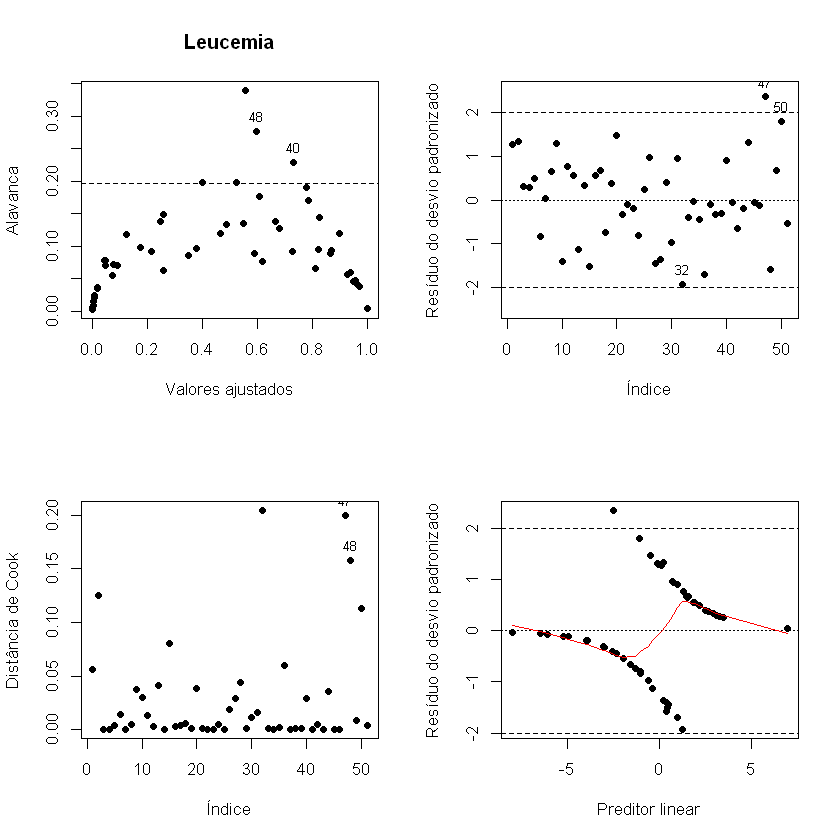

In [57]:
dl <- diag_glm(fit.leu, titulo = "Leucemia")
leu[c(2, 48, 32, 47), ]

Com resposta binária os gráficos de resíduo formam duas faixas (uma para $y = 0$ e outra para $y = 1$), o que é normal.

- **Alavanca:** referência $2p/n = 10/51 \approx 0{,}20$. Destacam-se **2 e 48** (≈ 0,34 e 0,28): a obs. 2 tem malignidade 35 e temperatura 1030 (a mais alta do lado satisfatório).
- **Resíduos:** só a **obs. 47** passa um pouco de 2 ($t_D \approx 2{,}35$); 32 fica perto (≈ −1,9). A 47 é um paciente com tratamento satisfatório apesar de ter 74 anos e temperatura relativamente alta (1002), perfil que o modelo associa a baixa probabilidade de sucesso.
- **Cook:** os maiores são **32, 47 e 48** (≈ 0,20; 0,20; 0,16).

Pontos fora do envelope: 0 de 51 (0.0%)


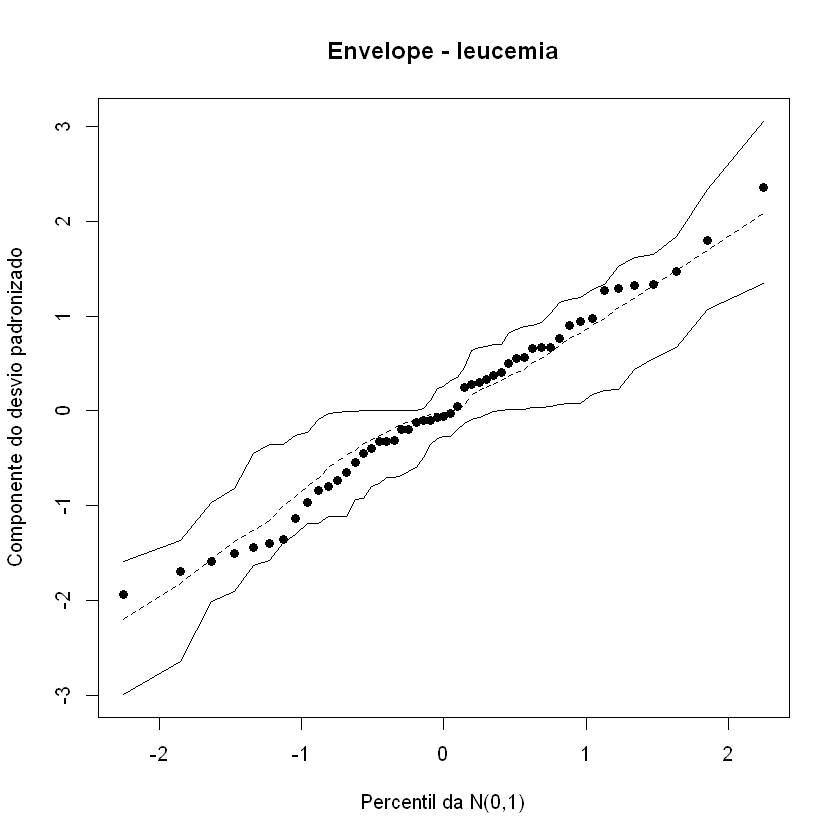

In [58]:
envelope_glm(fit.leu, main = "Envelope - leucemia")

Todos os pontos dentro do envelope (0 de 51). Não há evidência contra o modelo logístico.

In [59]:
for (k in c(32, 47, 48)) {
  ajk <- glm(trat ~ idade + infil + cel + temp, family = binomial, data = leu, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(fit.leu)) / coef(fit.leu) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 3))
}


Sem a observação 32 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept) -11.631   0.039
idade        -3.516   0.035
infil        28.094   0.057
cel          16.913   0.001
temp        -10.010   0.032

Sem a observação 47 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept)  37.454   0.009
idade        51.548   0.011
infil        25.718   0.074
cel          28.364   0.003
temp         36.654   0.008

Sem a observação 48 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept)  11.786   0.011
idade       -13.442   0.053
infil       -24.951   0.216
cel          14.616   0.002
temp         11.745   0.009


Retirando uma de cada vez as observações mais influentes, as estimativas variam bastante (até ≈ 50% no coeficiente de `idade` sem a obs. 47), o que é esperado com $n = 51$ e resposta binária. Mesmo assim, **nenhum sinal muda**; `cel` e `temp` continuam significativas a 5% em todos os casos, `idade` fica limítrofe só sem a obs. 48 (p ≈ 0,053) e `infil` oscila entre p ≈ 0,06 e 0,22. As conclusões são robustas e mantemos todas as observações.

## 5.4 Razões de chances

In [60]:
or <- exp(cbind(OR = coef(fit.leu), confint.default(fit.leu)))[-1, ]
round(or, 3)

# razões de chances para incrementos mais interpretáveis
inc <- c(idade = 10, infil = 10, cel = 5, temp = 10)
round(exp(inc * cbind(coef(fit.leu)[names(inc)], confint.default(fit.leu)[names(inc), ])), 3)

,OR,2.5 %,97.5 %
idade,0.942,0.893,0.992
infil,1.035,0.993,1.078
cel,1.502,1.163,1.939
temp,0.905,0.838,0.978


,,2.5 %,97.5 %
idade,0.547,0.324,0.925
infil,1.407,0.936,2.115
cel,7.642,2.130,27.412
temp,0.370,0.170,0.803


Razões de chances (RC) de tratamento satisfatório, mantidas as demais covariáveis fixas:

- **Idade:** RC por ano ≈ 0,94. **Cada 10 anos a mais** multiplica a chance de sucesso por ≈ **0,55** (IC 95%: 0,32 a 0,93): ≈ 45% a menos.
- **Células com leucemia na medula (`cel`):** RC por ponto percentual ≈ 1,50. **Cada 5 pontos percentuais a mais** multiplica a chance por ≈ **7,6** (IC: 2,1 a 27,4). Pacientes com mais células leucêmicas respondem melhor ao tratamento (provavelmente porque o tratamento age sobre essas células).
- **Temperatura máxima (`temp`, em ×10 °F):** 10 unidades = **1 °F**. Cada 1 °F a mais multiplica a chance por ≈ **0,37** (IC: 0,17 a 0,80): febre alta antes do tratamento reduz bastante a chance de sucesso.
- **Infiltração na medula (`infil`):** cada 10 pontos percentuais a mais multiplica a chance por ≈ 1,41, mas o efeito não é significativo a 5% (IC da RC inclui 1).

---
# Exercício 6 — Lagartos *grahani* e *opalinus* (Cap. 4, Ex. 24)

Número de lagartos *grahani* (`num`) no total de lagartos observados (`tot`, grahani + opalinus), segundo:

- `per`: período do dia (1 = manhã, 2 = meio-dia, 3 = tarde);
- `comp`: comprimento da madeira (1 = curta, 2 = comprida);
- `larg`: largura da madeira (1 = estreita, 2 = larga);
- `local`: local de ocupação (1 = claro, 2 = escuro).

Modelo: $Y_i \sim \text{Bin}(m_i, \pi_i)$, em que $\pi_i$ é a **proporção de grahani**. O ANODEV não é pedido.

In [61]:
gr <- read.table(paste0(caminho, "L4-Q6-C4-EX24-grahani.txt"), header = TRUE)
gr$per   <- factor(gr$per,   labels = c("manha", "meiodia", "tarde"))
gr$comp  <- factor(gr$comp,  labels = c("curta", "comprida"))
gr$larg  <- factor(gr$larg,  labels = c("estreita", "larga"))
gr$local <- factor(gr$local, labels = c("claro", "escuro"))
gr$prop  <- gr$num / gr$tot
gr

num,tot,per,comp,larg,local,prop
<int>,<int>,<fct>,<fct>,<fct>,<fct>,<dbl>
20,22,manha,curta,estreita,claro,0.9090909
8,9,meiodia,curta,estreita,claro,0.8888889
4,8,tarde,curta,estreita,claro,0.5000000
13,13,manha,comprida,estreita,claro,1.0000000
8,8,meiodia,comprida,estreita,claro,1.0000000
12,12,tarde,comprida,estreita,claro,1.0000000
8,11,manha,curta,larga,claro,0.7272727
4,5,meiodia,curta,larga,claro,0.8000000
5,8,tarde,curta,larga,claro,0.6250000


São 23 combinações (a combinação meio-dia/comprida/larga/claro não aparece). Os totais variam de 2 a 92 lagartos, então as proporções observadas têm precisões bem diferentes.

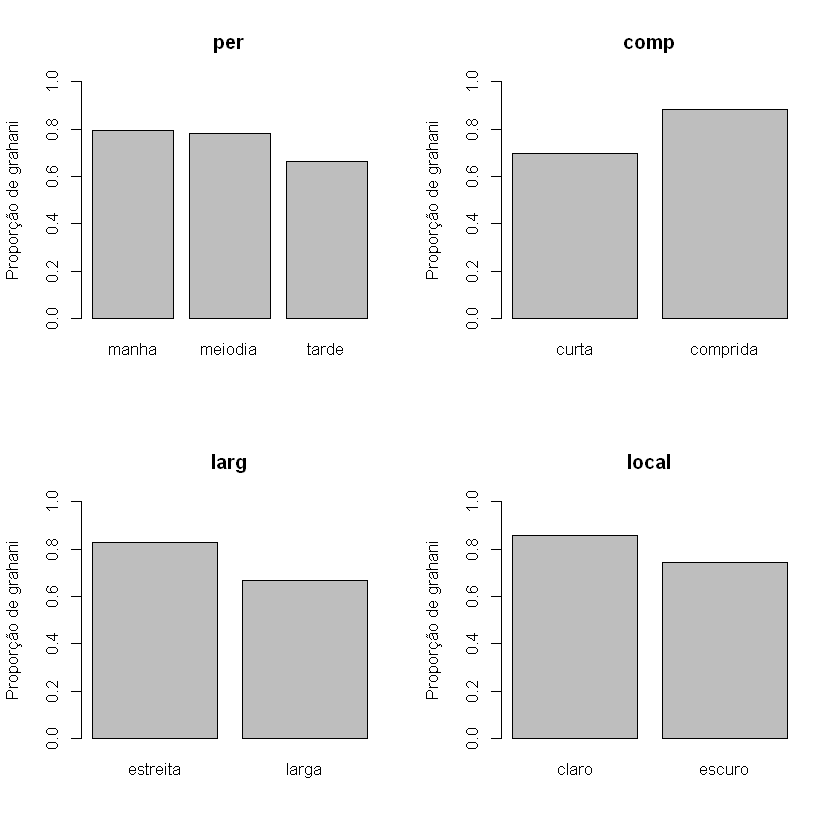

In [62]:
par(mfrow = c(2, 2))
for (v in c("per", "comp", "larg", "local")) {
  pv <- tapply(gr$num, gr[[v]], sum) / tapply(gr$tot, gr[[v]], sum)
  barplot(pv, ylim = c(0, 1), main = v, ylab = "Proporção de grahani")
}
par(mfrow = c(1, 1))

Proporções marginais de grahani: maior de manhã e ao meio-dia do que à tarde, maior em madeira **comprida**, maior em madeira **estreita** e maior em local **claro**. Essas são proporções brutas; o modelo controla os demais fatores.

## 6.1 (i) Modelo logístico sem interação e testes da razão de verossimilhanças (10%)

In [63]:
fit.gr <- glm(cbind(num, tot - num) ~ per + comp + larg + local, family = binomial, data = gr)
summary(fit.gr)
drop1(fit.gr, test = "Chisq")


Call:
glm(formula = cbind(num, tot - num) ~ per + comp + larg + local, 
    family = binomial, data = gr)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)    1.9447     0.3415   5.695 1.23e-08 ***
permeiodia     0.2271     0.2502   0.908 0.363984    
pertarde      -0.7368     0.2990  -2.464 0.013730 *  
compcomprida   1.1300     0.2571   4.395 1.11e-05 ***
larglarga     -0.7626     0.2113  -3.610 0.000306 ***
localescuro   -0.8473     0.3224  -2.628 0.008585 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.102  on 22  degrees of freedom
Residual deviance: 14.205  on 17  degrees of freedom
AIC: 83.029

Number of Fisher Scoring iterations: 4


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,14.20457,83.02879,NA,NA
per,2,25.80171,90.62592,11.597136,3.031893e-03
comp,1,36.27080,103.09501,22.066228,2.634034e-06
larg,1,27.33457,94.15878,13.129994,2.906057e-04
local,1,21.89172,88.71593,7.687146,5.561550e-03


Testes da razão de verossimilhanças para retirar cada fator (com os demais no modelo):

| Fator | LRT | g.l. | p-valor |
|---|---|---|---|
| período | 11,60 | 2 | 0,003 |
| comprimento | 22,07 | 1 | < 0,001 |
| largura | 13,13 | 1 | < 0,001 |
| local | 7,69 | 1 | 0,006 |

**Todos os quatro efeitos são significativos ao nível de 10%** (e também a 1%). Pelo teste de Wald, o meio-dia não difere da manhã (p ≈ 0,36), mas a tarde sim (p ≈ 0,014).

## 6.2 (ii) Inclusão de cada interação de 1ª ordem separadamente (5%)

In [64]:
add1(fit.gr, scope = ~ . + (per + comp + larg + local)^2, test = "Chisq")

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,14.20457,83.02879,NA,NA
per:comp,2,13.68203,86.50624,0.52254054,0.7700728
per:larg,2,14.16158,86.98579,0.04299651,0.9787312
per:local,2,12.93206,85.75627,1.27251177,0.5292704
comp:larg,1,13.92297,84.74719,0.28159831,0.5956555
comp:local,1,11.98426,82.80847,2.22031391,0.1362054
larg:local,1,14.13255,84.95676,0.07202314,0.7884135


Cada interação foi testada **sozinha**, adicionada ao modelo de efeitos principais:

| Interação | LRT | g.l. | p-valor |
|---|---|---|---|
| per:comp | 0,52 | 2 | 0,770 |
| per:larg | 0,04 | 2 | 0,979 |
| per:local | 1,27 | 2 | 0,529 |
| comp:larg | 0,28 | 1 | 0,596 |
| comp:local | 2,22 | 1 | 0,136 |
| larg:local | 0,07 | 1 | 0,788 |

**Nenhuma interação é significativa ao nível de 5%** (a menor p-valor é 0,136, de comp:local). O modelo final é o de **efeitos principais**.

## 6.3 (iii) Interpretação

In [65]:
round(exp(cbind(RC = coef(fit.gr), confint.default(fit.gr))), 3)

,RC,2.5 %,97.5 %
(Intercept),6.991,3.580,13.653
permeiodia,1.255,0.769,2.049
pertarde,0.479,0.266,0.860
compcomprida,3.096,1.870,5.124
larglarga,0.466,0.308,0.706
localescuro,0.429,0.228,0.806


Razões de chances de um lagarto ser **grahani** (em vez de opalinus), mantidos os demais fatores:

- **Período:** meio-dia vs manhã: RC ≈ 1,26 (IC inclui 1, sem diferença); **tarde vs manhã: RC ≈ 0,48** (IC: 0,27 a 0,86).
- **Comprimento:** **madeira comprida vs curta: RC ≈ 3,10** (IC: 1,87 a 5,12).
- **Largura:** **madeira larga vs estreita: RC ≈ 0,47** (IC: 0,31 a 0,71).
- **Local:** **escuro vs claro: RC ≈ 0,43** (IC: 0,23 a 0,81).

**Em linguagem não técnica:** os dois tipos de lagarto têm preferências diferentes de lugar e de horário.

- O **grahani** gosta mais de **galhos compridos e finos**, em **lugares ensolarados (claros)**, e aparece mais **de manhã e ao meio-dia**. Em madeira comprida, a chance de um lagarto encontrado ser grahani é cerca de **3 vezes** maior do que em madeira curta.
- O **opalinus**, ao contrário, aparece relativamente mais em **galhos grossos (largos)**, em **lugares de sombra (escuros)** e **à tarde**: nessas condições a chance de o lagarto ser grahani cai mais ou menos pela **metade**.

Como não há interações, essas preferências se somam: a combinação "manhã, madeira comprida, estreita, local claro" é onde a proporção de grahani é maior, e "tarde, curta, larga, escuro" onde é menor.

In [66]:
grade_gr <- expand.grid(per = levels(gr$per), comp = levels(gr$comp), larg = levels(gr$larg), local = levels(gr$local))
grade_gr$p_grahani <- round(predict(fit.gr, newdata = grade_gr, type = "response"), 3)
grade_gr[order(-grade_gr$p_grahani), ][c(1:3, 22:24), ]

,per,comp,larg,local,p_grahani
,<fct>,<fct>,<fct>,<fct>,<dbl>
5,meiodia,comprida,estreita,claro,0.964
4,manha,comprida,estreita,claro,0.956
11,meiodia,comprida,larga,claro,0.927
15,tarde,curta,estreita,escuro,0.589
19,manha,curta,larga,escuro,0.583
21,tarde,curta,larga,escuro,0.401


As proporções estimadas confirmam: a maior proporção de grahani (≈ 0,96) ocorre de meio-dia/manhã em madeira comprida, estreita e em local claro; a menor (≈ 0,40) à tarde, em madeira curta, larga e em local escuro, onde os **opalinus passam a ser maioria**.

## 6.4 (d) Análise de diagnóstico completa do modelo binomial

In [67]:
c(desvio = deviance(fit.gr), gl = df.residual(fit.gr),
  desvio_gl = deviance(fit.gr) / df.residual(fit.gr),
  p_valor = 1 - pchisq(deviance(fit.gr), df.residual(fit.gr)))

desvio         gl  desvio_gl    p_valor 
14.2045732 17.0000000  0.8355631  0.6525718

Desvio = 14,2 com 17 g.l. ($D/\text{gl} \approx 0{,}84$, p ≈ 0,65): **bom ajuste e nenhum sinal de sobredispersão**.

Referência 2p/n = 0.522 


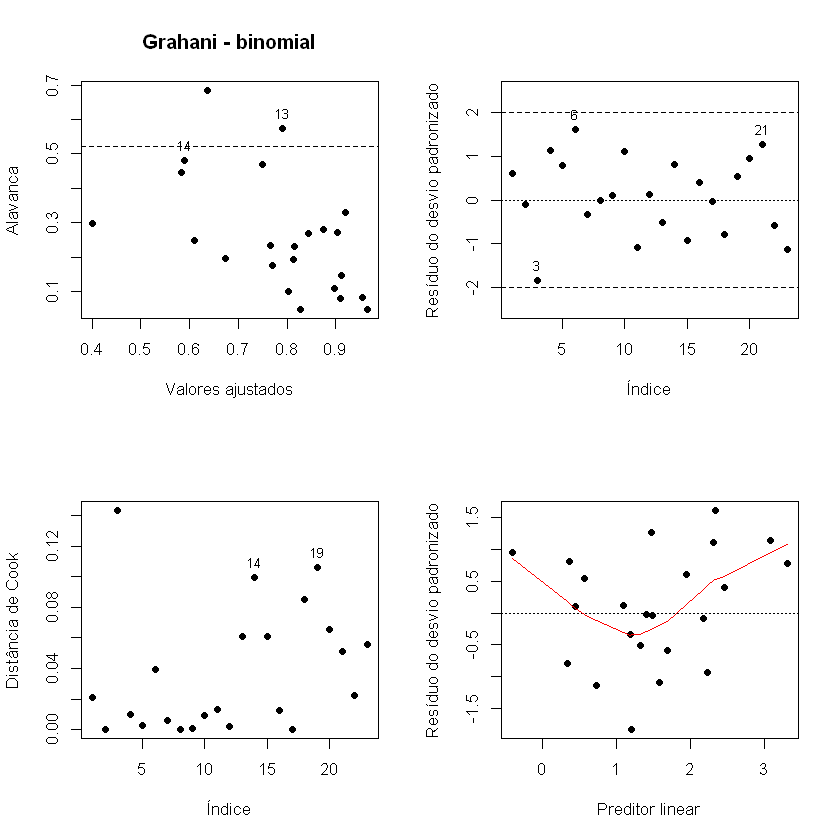

In [68]:
dg <- diag_glm(fit.gr, titulo = "Grahani - binomial")

- **Alavanca:** referência $2p/n = 12/23 \approx 0{,}52$. As **obs. 19 e 13** ficam acima (≈ 0,68 e 0,57): são as células com os maiores totais (92 e 89 lagartos), naturalmente com mais peso.
- **Resíduos:** todos dentro de ±2 (maior em módulo: obs. 3, ≈ −1,8).
- **Cook:** todas pequenas (máximo ≈ 0,14 na obs. 3), nenhum ponto influente.
- **Resíduo × preditor:** sem tendência.

Pontos fora do envelope: 0 de 23 (0.0%)


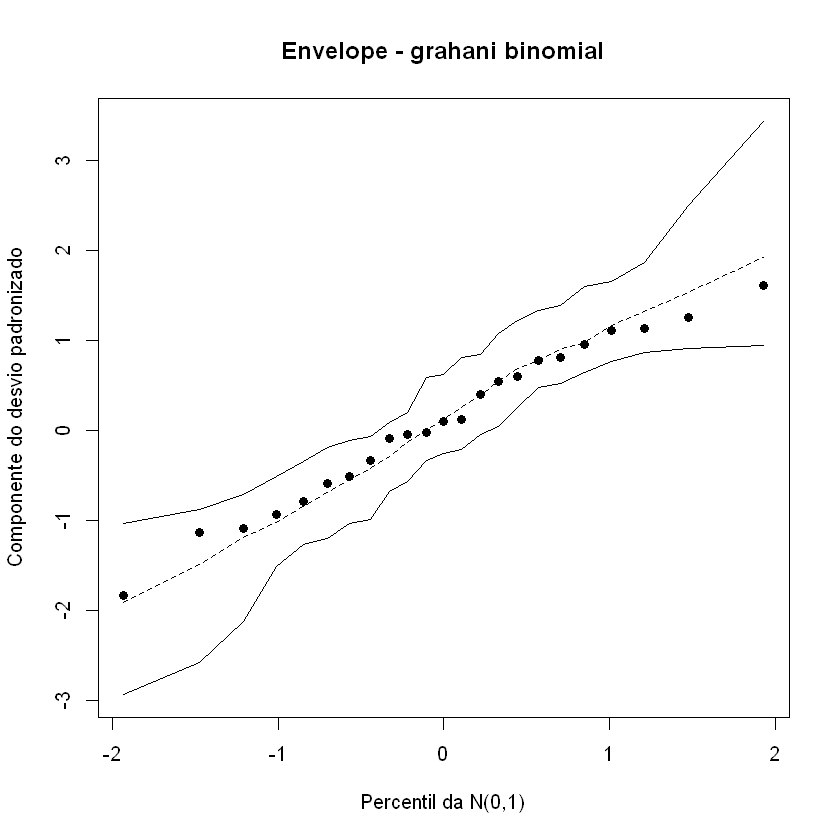

In [69]:
envelope_glm(fit.gr, main = "Envelope - grahani binomial")

Nenhum ponto fora do envelope. **O modelo logístico binomial de efeitos principais parece adequado**: não há falta de ajuste, sobredispersão, pontos discrepantes ou influentes.

## 6.5 (e) Modelo beta-binomial

Mesmo com o binomial adequado, ajustamos o **beta-binomial** no GAMLSS (`family = BB`). Nele $E(Y) = m\mu$ e
$$\text{Var}(Y) = m\mu(1-\mu)\left[1 + \frac{(m-1)\sigma}{1+\sigma}\right],$$
e o binomial é o caso $\sigma \to 0$. Usamos ligação logit para $\mu$ (a mesma interpretação em razões de chances) e log para $\sigma$.

In [ ]:
fit.bi <- gamlss(cbind(num, tot - num) ~ per + comp + larg + local, family = BI, data = gr, trace = FALSE)
fit.bb <- gamlss(cbind(num, tot - num) ~ per + comp + larg + local, sigma.formula = ~ 1, family = BB,
                 data = gr, trace = FALSE, control = gamlss.control(n.cyc = 200))
summary(fit.bb)
fitted(fit.bb, "sigma")[1]

As estimativas de $\mu$ no beta-binomial ficam **praticamente idênticas** às do binomial (por exemplo, comprida ≈ 1,13 e larga ≈ −0,76). O $\log\hat\sigma$ vai para um valor muito negativo (com erro-padrão enorme), ou seja, $\hat\sigma \approx 0$: **os dados não têm variabilidade extra-binomial**, e o beta-binomial se reduz ao binomial.

In [71]:
GAIC(fit.bi, fit.bb)
LR.test(fit.bi, fit.bb)

,df,AIC
,<dbl>,<dbl>
fit.bi,6,83.02879
fit.bb,7,85.22968


ERROR: Error in LR.test(fit.bi, fit.bb): The null model has smaller deviance than the alternative 
The models should be nested


O AIC do beta-binomial é ≈ 2 unidades maior (≈ 85,0 contra 83,0): paga um parâmetro a mais ($\sigma$) sem melhorar a verossimilhança. O teste da razão de verossimilhanças dá estatística ≈ 0 (p ≈ 1; como $\sigma = 0$ está na fronteira, o p-valor correto seria a metade, que continua ≈ 0,5). **Não rejeitamos o binomial.**

### Modelo final beta-binomial

In [ ]:
drop1(fit.bb)

Retirando cada fator do beta-binomial, todos aumentam bastante o AIC e têm LRT significativos (período ≈ 11,6; comprimento ≈ 20,1; largura ≈ 12,5; local ≈ 7,7), valores próximos aos do binomial (nos modelos reduzidos o $\sigma$ pode absorver um pouco da variação, por isso alguns LRT ficam ligeiramente menores). Como no item (ii), as interações também não entram. **O modelo final beta-binomial tem os quatro efeitos principais e $\sigma$ constante.**

In [ ]:
# também poderíamos deixar sigma depender de algum fator; checamos com stepGAIC sobre sigma
fit.bb.s <- stepGAIC(fit.bb, scope = list(lower = ~ 1, upper = ~ per + comp + larg + local),
                     what = "sigma", trace = FALSE)
formula(fit.bb.s, "sigma")

O `stepGAIC` aplicado a $\sigma$ mantém $\sigma$ constante (`~ 1`): nenhum fator explica variação na dispersão. O modelo final é o mesmo.

### Diagnóstico do beta-binomial

In [ ]:
plot(fit.bb)

Os resíduos quantílicos aleatorizados não têm tendência contra os ajustados nem contra o índice, a densidade é aproximadamente simétrica e o QQ-plot está próximo da reta. Média ≈ 0 e variância ≈ 1, compatíveis com $N(0,1)$.

In [ ]:
rqres.plot(fit.bb, howmany = 50, plot = "all")

As 50 realizações dos resíduos quantílicos (aleatorizados porque a resposta é discreta) ficam todas próximas da reta. Nenhuma realização mostra desvio sistemático.

In [ ]:
wp(fit.bb)

O *worm plot* fica dentro das bandas de 95%, sem forma de U, S ou inclinação: **média, variância, assimetria e curtose** do beta-binomial são compatíveis com os dados. O diagnóstico é tão bom quanto o do binomial, o que é esperado já que os dois modelos coincidem.

In [ ]:
# resíduos quantílicos contra os fatores
rq <- resid(fit.bb)
par(mfrow = c(2, 2))
for (v in c("per", "comp", "larg", "local")) { boxplot(rq ~ gr[[v]], main = v, ylab = "Resíduo quantílico"); abline(h = 0, lty = 2) }
par(mfrow = c(1, 1))

Os resíduos quantílicos ficam centrados em zero e com dispersão parecida em todos os níveis de cada fator: não há indício de efeito faltando na média nem na dispersão.

### Interpretação das estimativas do beta-binomial

In [ ]:
est.bb <- coef(fit.bb, "mu")
ic.bb  <- confint(fit.bb, what = "mu")
round(exp(cbind(RC = est.bb, ic.bb)), 3)

Como $\hat\sigma \approx 0$, as razões de chances do beta-binomial são as mesmas do binomial:

- **tarde vs manhã:** RC ≈ 0,48: à tarde a chance de um lagarto ser grahani cai pela metade;
- **meio-dia vs manhã:** RC ≈ 1,26 (não significativa);
- **comprida vs curta:** RC ≈ 3,10: em madeira comprida a chance de ser grahani é ≈ 3 vezes maior;
- **larga vs estreita:** RC ≈ 0,47: em madeira larga a chance cai ≈ 53%;
- **escuro vs claro:** RC ≈ 0,43: na sombra a chance cai ≈ 57%.
- **$\sigma$:** $\hat\sigma \approx 0$, ou seja, as proporções de grahani nas diferentes combinações **não variam além do que a binomial já prevê**.

**Conclusão do item (e):** o beta-binomial confirma o modelo binomial. Não há sobredispersão, o parâmetro extra não é necessário e as interpretações sobre as preferências dos dois lagartos (grahani: galhos compridos, finos, ao sol, de manhã/meio-dia; opalinus: galhos grossos, sombra, à tarde) continuam as mesmas. Pelo princípio da parcimônia, o **modelo binomial** é o preferido.